# SignalBrief — A LangGraph Competitive Intelligence & Cited RAG Research Engine

An AI **agent** that turns a company name into a fully cited competitive-intelligence report in minutes. It decides on its own when to read the company's filings (RAG over an in-memory vector store) and when to search the live web (Tavily), and attributes every figure to a source file + page or a URL.

Built with **LangGraph** and `gpt-4o-mini`, then **evaluated against a naive-RAG baseline** on a 24-case golden dataset using deterministic checks and an LLM-as-judge.

# **Problem Scenario**

**Allied FinServ** is a mid-sized investment management firm that invests in global listed equities for institutional and high-net-worth clients. Its research team covers a large universe of listed companies, and a core output of that team is the **competitive intelligence report**: a profile of one company and its competitive landscape, covering financial performance, competitor positioning, recent developments and risks. Portfolio managers and risk teams use these reports to make buy, hold, sell and position-sizing decisions.

Today, one competitive intelligence report takes an analyst **3-5 working days**, and about **60%** of that time is spent collecting and copying data from SEC filings, shareholder decks, earnings material and news sites. The work is slow and error-prone:

- **Manual research bottleneck:** analysts spend most of their time on data collection, which limits the number of companies each analyst can cover.
- **Fragmented information:** key figures are locked in static PDF filings, while market-moving updates arrive through live news. Cross-referencing the two is done by hand.
- **Insight latency:** by the time a report is finished, it is often days behind the latest news.
- **Inconsistency:** quality depends on the individual analyst, and figures are not always traceable to a source.

An earlier trial of a general-purpose chat assistant was dropped because it produced figures that analysts could not verify and had no access to current news. Any new system must therefore be **grounded in source documents, cite every claim, and combine static filings with live web data**.

# **Business Objective**

Allied FinServ wants an **agentic market intelligence system** that, given a company name, researches the company using its filings and the live web and produces a **cited competitive intelligence report** in minutes rather than days. The system will be piloted on **Tesla**.

Because the business needs to *trust* the output, the project does not stop at building the agent. It also **evaluates** the agent against a simpler baseline (a naive RAG pipeline) using a golden dataset and deterministic checks, so that the team can see where the agent is reliable and where it still fails.

# **Solution Workflow**

The proposed Market Competitor Intelligence workflow is a **single research agent** with two tools:
- The user provides a company name (eg: `Tesla`) or a research question.
- The **Research Agent** (an LLM with tool calling) decides what it needs, calls a tool, reads the result and repeats until it has enough evidence:
    - The `pdf_search_tool` retrieves cited passages from the filings and decks in the document corpus.
    - The `tavily_web_search_tool` retrieves current news, market data and information about competitors that are not in the documents from the internet.
- When the agent stops calling tools, it returns a **cited answer** or a full **competitive intelligence report**.
- In the evaluation stage, the agent and a **naive RAG baseline** answer the same golden questions. Deterministic checks score both on retrieval, tool use and answer accuracy, and an **LLM judge** grades whether each answer is correct.

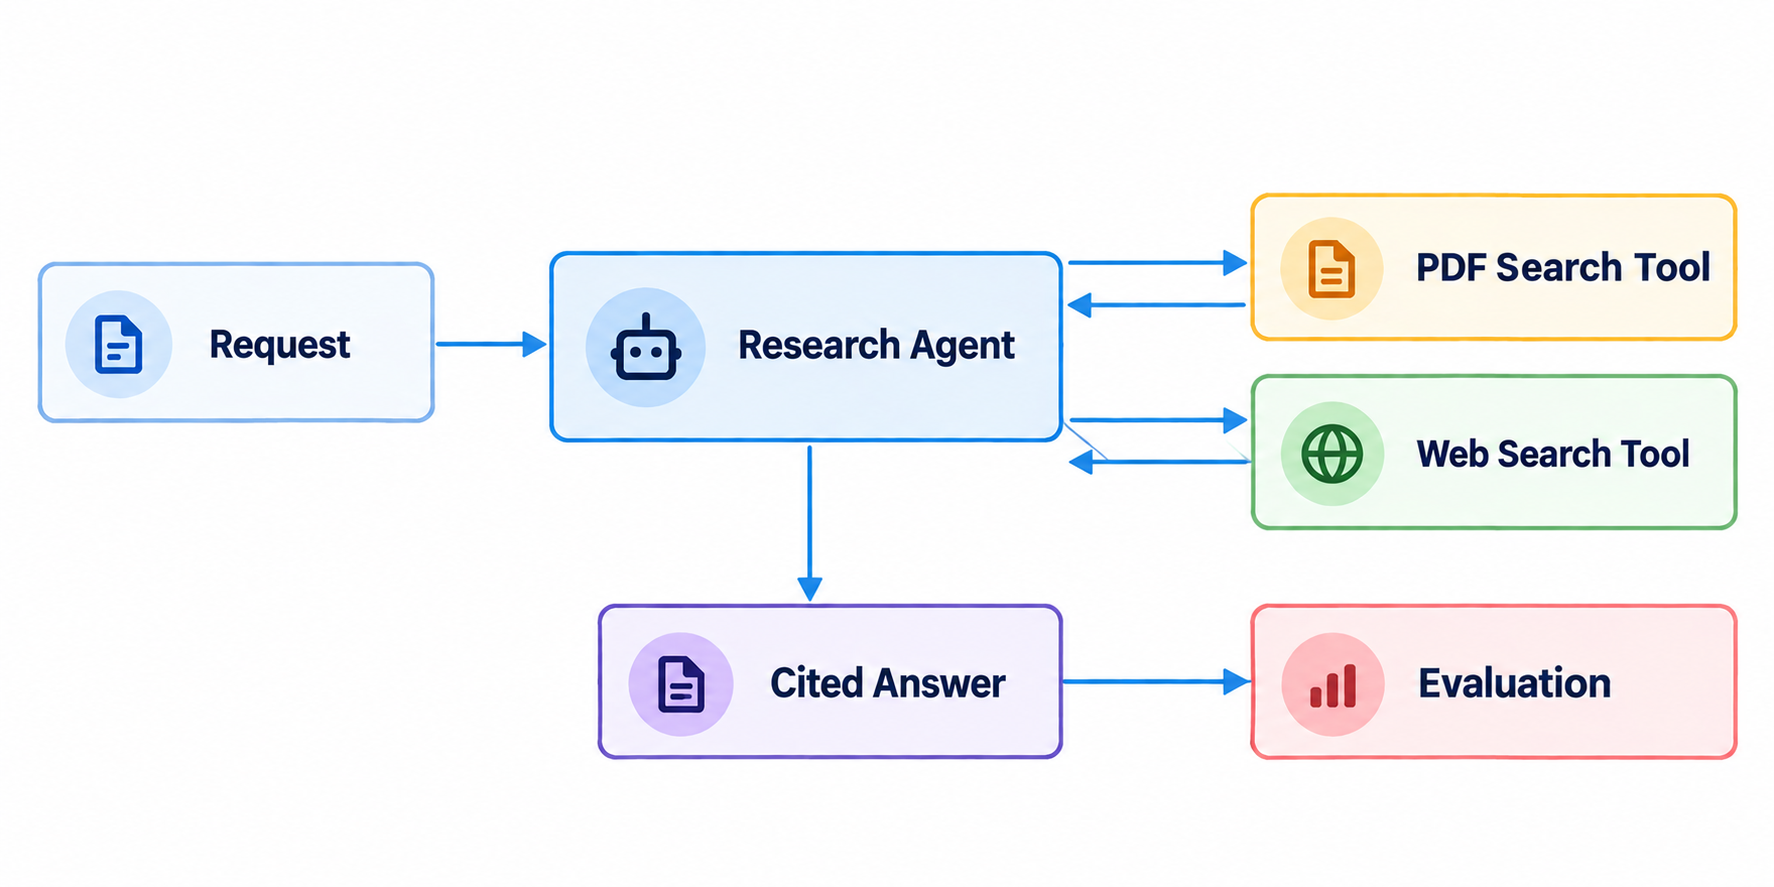

# **Project Overview**

The project is structured into the following six phases:

**1. Environment Setup**

- **Library Installation**: Core frameworks/ libraries are installed.
- **Infrastructure & Credentials**: Code to configure API key for OpenAI and Tavily are loaded from `config.json`.
- **Model Calibration**: The chat model and the embedding model are configured.

**2. Tool Configuration & Intent Routing**

- **Hybrid Search Tools**: The `tavily_web_search_tool` searches the live web and the `pdf_search_tool` searches the document corpus, returning each passage with its file name and page number.
- **LLM Binding**: The tools are bound to the LLM so that it can decide which source to query for each information need.

**3. Research Agent and Naive RAG Baseline**

- **Research Agent**: A LangGraph workflow with two nodes, `agent` and `tools`, connected in a loop. The agent keeps calling tools until it has the evidence it needs, then answers with citations.
- **Trajectory capture**: Every run records which tools were called, with what arguments, and what they returned, so that the agent's behaviour can be evaluated.
- **Naive RAG Baseline**: A single retrieval step followed by a single LLM call, used as a point of comparison.

**4. Report Generation**

- The agent researches Tesla and writes a structured competitive intelligence report with a fixed template, which is displayed and saved.

**5. Evaluation**

- A **golden dataset** of 24 hand-written cases (PDF facts, conflicts, hybrid, web and unanswerable questions) is loaded from a CSV file: every gold value is checked against its source.
- **Deterministic checks** test each layer of the system: retrieval (was the right evidence found?), tool use (were the right tools called?) and the answer (correct figure, valid citations, correct refusal of undisclosed information).
- An **LLM judge** (a separate, stronger model) grades each answer as correct, partially correct or incorrect against the expected answer, and its verdicts are checked against the deterministic checks.
- A **scorecard** is created that compares the agent with naive RAG, and failed cases are traced to their cause.

**6. Concluding Remarks**

- Key takeaways, expected business impact and improvements to the workflow.

# **Data Overview**

The project uses two data streams:

- A realtime **live web data** through the **Tavily Search API**, for current news, market data and competitors that are not in the documents.
- **A document corpus** of five complete public documents, provided in `data.zip`.

The archive unzips to a `data/` folder that contains the five PDFs and `golden_dataset.csv` (24 hand-written evaluation cases used in Section 5).

NOTE: *The latest filings in the corpus cover Q2 2026 (quarter ended June 30, 2026). Anything more recent, and any company that is not in the corpus (for example BYD or Ford), must come from the web search tool.*

# **Installing and Importing the Necessary Libraries**

* The `openai` library is the official OpenAI SDK for interacting with models like gpt-4o-mini, used in the notebook.

* `langchain` framework can be used for building applications using LLMs with tool-use, memory, chains, and agents.

* `langchain-openai` provides the integration layer between LangChain and the OpenAI SDK.

* `langchain-community` consists of community-contributed integrations (tools, loaders, retrievers, etc.) for LangChain.

* `langchain-tavily` is the official Tavily integration for LangChain and replaces the deprecated `TavilySearchResults` tool.

* `langgraph` will be used for graph-based workflow engine for building LLM agents with stateful and cyclic logic.

* `pypdf` library will be used for reading and extracting text from PDF files.

In [1]:
# Installing the Libraries
%pip install -q openai==1.66.3 langchain==0.3.20 langchain-openai==0.3.9 langchain-community==0.3.19 langchain-tavily==0.2.17 langgraph==0.3.21 pypdf==5.4.0

Note: you may need to restart the kernel to use updated packages.


## Importing the Libraries

In [2]:
# Standard library and notebook helpers
import json
import os
import re
import time
from datetime import datetime
from typing import Literal, Optional

import pandas as pd
from IPython.display import Image, Markdown, display

# LangChain and LangGraph
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import PromptTemplate, format_document
from langchain_core.runnables import RunnableConfig
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain.tools import tool
from langchain.tools.retriever import create_retriever_tool
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_tavily import TavilySearch
from langgraph.errors import GraphRecursionError
from langgraph.graph import END, START, MessagesState, StateGraph
from pydantic import BaseModel, Field

/Users/dreamcclure/PycharmProjects/JHU_AI_CodeProjects/JHU_Week16PyC/.venv312/lib/python3.12/site-packages/langgraph/checkpoint/base/__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


# **1. Environment Setup**

## 1.1 Model Selection

The following code section establishes the three model roles used throughout the project. We define separate models for the **generation**, **evaluation** (judge model) and the **embedding model**: generation, evaluation, and retrieval each have a distinct responsibility.

The following table describes in deatil the models used in the project, its function and the reason for selecting the model.

| Model | Function | Reason for selection |
| --- | --- | --- |
| `gpt-4o-mini` | Chat model for the research agent, the naive RAG baseline and the report | Reliable tool calling at low cost and latency, which matters because the agent makes several calls per question and the evaluation runs both systems on every golden question. Temperature 0 keeps the outputs as repeatable as possible. |
| `gpt-4o` | LLM judge that grades the correctness of every answer during Evaluation section. | It's generally recommended to use a stronger model than the one generating the answers. |
| `text-embedding-3-small` | Embeds the document chunks and queries for semantic search | Strong retrieval quality for English financial text at a very low cost: embedding the corpus costs around one cent. |

NOTE: The Judge LLM (`gpt-4o`) is called once per answer (total of 48 calls), so the higher price per token adds little to the total cost.

## 1.2 Initialize OpenAI configuration and the models

The next cells turn the selected models and API credentials into reusable Python objects.

In [3]:
# Load credentials from config.json
config_file = "config.json"
with open(config_file, "r", encoding="utf-8") as file:
    config = json.load(file)

os.environ["OPENAI_API_KEY"] = config["API_KEY"]
if config.get("OPENAI_API_BASE"):
    os.environ["OPENAI_BASE_URL"] = config["OPENAI_API_BASE"]

MODEL = "gpt-4o-mini" # research agent and naive RAG
JUDGE_MODEL = "gpt-4o" # LLM-as-a-judge
EMBED_MODEL = "text-embedding-3-small" # document and query embeddings

The following code block initializes Tavily API Key for performing web search.

You can signup/ login to [Tavily](https://www.tavily.com/) by creating a free account.

Tavily provides **Free Plan** which provides 1,000 free API Credits every month.

In [4]:
# Make the Tavily key available to the LangChain search tool.
tavily_api_key = config.get("TAVILY_API_KEY")
if tavily_api_key:
    os.environ["TAVILY_API_KEY"] = tavily_api_key

## 1.3 LLM and Embedding Model Initialization

We define three reusable model interfaces:

- `llm` generates the research-agent and baseline answers.
- `judge_llm` evaluates answer correctness independently.
- `embedding_model` converts document chunks and queries into vectors for semantic retrieval.

In [5]:
# Instantiate the chat and embedding models through LangChain abstractions.
llm = ChatOpenAI(model=MODEL, temperature=0)
judge_llm = ChatOpenAI(model=JUDGE_MODEL, temperature=0)
embedding_model = OpenAIEmbeddings(model=EMBED_MODEL)

In [6]:

# Quick connection test
print("LLM says:", llm.invoke("Say hello in 3 words").content)
print("Embedding length:", len(embedding_model.embed_query("hi")))


LLM says: Hello, how are you?


Embedding length: 1536


## 1.4 Get the Current Date

The current date and `LATEST_FILING_PERIOD` give the agent an explicit time boundary for deciding whether the PDFs are sufficient or a live web search is needed.

The competitor analysis requires the use of **historical facts from a fixed document corpus** along with **current information from the web**.

We'll initialize a variable `current_date` that keeps track of the current date for the report generation process. This variable will used to provide a reference date for restricting the search results to the relevant timeframe and in the final report generation process.

We also record `LATEST_FILING_PERIOD`, the most recent period covered by the document corpus. The agent uses it to decide when the documents are enough and when it must search the web for newer information.

In [7]:
# Get the current date
current_date = datetime.now().strftime("%Y-%m-%d")
current_date

# The most recent period covered by the PDF corpus to Q2 2026
LATEST_FILING_PERIOD = "Q2 2026 (quarter ended June 30, 2026)"

The current date and `LATEST_FILING_PERIOD` give the agent an explicit time boundary for deciding whether the PDFs are sufficient or a live web search is needed.

# **2. Setting up the Tools**

In this section, we'll set up the Tools required to solve the business objective, namely Tavily search tool that searches for information online and the PDF search tool that retrieves information from the document corpus.

## 2.1 Tavily Search Tool

The documents in the corpus stop at Q2 2026, and the LLM's own knowledge stops at its training cutoff. To answer questions about recent news, current market data or companies that are not in the documents (for example BYD or Ford), the agent needs a live connection to the internet. The `tavily_web_search_tool` provides it.

The tool wraps `TavilySearch` from the `langchain-tavily` package, a search API designed for LLM agents: instead of raw web pages, it returns short, relevant extracts. For every query the tool returns the top `num_results` results, each with:

- a **title**, so the agent can judge relevance at a glance,
- a **short extract** of the page, cut to 800 characters to keep the agent's context small,
- the **source URL**, so every web fact in an answer can be cited and verified.

The optional `time_range` argument (`day`, `week`, `month` or `year`) restricts results to recently published pages. It suits questions about the *latest* news. It is not suitable for a figure from a past quarter, because the articles reporting that figure were published shortly after the quarter ended and fall outside a short time window.

**How the agent uses this function.** The `@tool` decorator turns the Python function into a tool the LLM can call. The LLM never sees the code: it sees the function's **name**, its **arguments** (from the type hints) and its **docstring**. The docstring therefore acts as the tool's instruction manual, telling the LLM what the tool is for and when to use it.

**Error handling.** If the search fails (no API key, network error, rate limit), the tool returns an error message as text instead of raising an exception. The agent reads the message like any other tool result and can try again or answer without web data, and the notebook keeps running.

In [8]:
@tool
def tavily_web_search_tool(
    query: str,
    num_results: int = 5,
    time_range: Optional[Literal["day", "week", "month", "year"]] = None,
) -> str:
    # The docstring below is sent to the LLM as the tool description: it decides when the
    # tool is chosen, so it states the purpose and when to use it, in plain language.
    """Search the live web for current news, market data, analyst views and competitors.
    Use it for anything more recent than the documents or about companies not in the documents.
    Set time_range ('day', 'week', 'month' or 'year') to keep only recent pages, e.g. 'month' for the latest news."""
    num_results = num_results  # cap the API credits used per call
    try:
        # Create the Tavily client for this call. topic="general" searches the whole web;
        # time_range=None means no date filter.
        search = TavilySearch(max_results=num_results, topic="general", time_range=time_range)
        response = search.invoke({"query": query})

        # Tavily reports some failures (for example a missing API key) inside the response
        # instead of raising an exception, so check for an "error" key first.
        if isinstance(response, dict) and response.get("error"):
            return f"Error performing web search: {response['error']}"

        # A successful response is a dict with a "results" list; anything else is treated as empty.
        results = response.get("results", []) if isinstance(response, dict) else []
        if not results:
            return "No web search results found."

        # Format each result as a numbered block: title, a shortened extract and its URL.
        # The agent copies the URL after "Source:" into its citations.
        formatted = []
        for index, result in enumerate(results, start=1):
            # Keep only the first 800 characters: enough evidence to answer, without filling
            # the agent's context window with whole web pages.
            content = (result.get("content") or "No content available")[:800]
            formatted.append(
                f"Result {index}: {result.get('title', 'No title')}\n"
                f"{content}\n"
                f"Source: {result.get('url', 'No URL')}"
            )

        # One string for the agent, with a blank line between results.
        return "\n\n".join(formatted)

    except Exception as exc:
        # Return the error as text instead of raising it: the agent can read it and react,
        # and a single failed search does not stop the notebook.
        return f"Error performing web search: {exc}"

The following code tests the tool directly, before it is given to the agent. Testing each tool on its own first makes problems easy to locate: if this cell prints an error, the cause is the tool or the API key, not the agent. The output should show up to five numbered results, each with a title, an extract and a `Source:` URL.

In [9]:
# Call the tool directly with a sample query. Tools take their arguments as a dictionary,
# exactly as the agent will pass them later. Including the date steers the search towards recent news.
search_result = tavily_web_search_tool.invoke({"query": f"Tesla latest news {current_date}"})

# Print only the first 2,000 characters to keep the notebook output readable.
print(search_result[:2000])

Result 1: 2026
238.   ↑Joseph Ataman, Catherine Nicholls, Sana Noor Haq (October 17, 2026). "Half a million protesters sweep France in major show of youth unrest | CNN". _CNN_. Retrieved October 18, 2026.`{{cite news}}`: CS1 maint: multiple names: authors list (link)
239.   ↑"Результаты — сводка". _neshodilina.netlify.app_. Retrieved September 22, 2026. [...] This page was last edited on 18 October 2026, at 10:00(UTC).
   Page was rendered with Parsoid.
   Text is available under the Creative Commons Attribution-ShareAlike 4.0 License; additional terms may apply. By using this site, you agree to the Terms of Use and Privacy Policy. Wikipedia® is a registered trademark of the Wikimedia Foundation, Inc., a non-profit organization. [...] 255.   ↑"Mecca alliance agrees to activate collective deterrence measu
Source: https://en.wikipedia.org/wiki/2026

Result 2: DevDay 2026 Recap
Image 2: Teaching students to think and learn through questions — Cover

Teaching students to think and learn th

**Key idea.** The web search tool is the agent's **real-time external information channel**: the documents provide reported figures, and this tool provides everything newer or outside the corpus.

Its output is deliberately compact and source-labelled. Each result carries just enough text to answer the question and a URL to cite, so the LLM gets the evidence it needs without spending its context window on whole web pages.

## 2.2 PDF Search Tool

The web search tool gives the agent access to the live internet. The PDF search tool gives it access to the **document corpus** provided in `data.zip`. These documents are the authoritative source for reported financial and operating figures.

An LLM cannot read 680+ pages for every question, so we use **retrieval-augmented generation (RAG)**: the documents are split into small chunks and stored as vectors, and for each question only the most relevant chunks are retrieved and shown to the LLM.

The work is split into two sub-sections:
- **2.2.1 Vector store initialization** (done once): load the PDF pages with LangChain's [PyPDFDirectoryLoader](https://python.langchain.com/docs/integrations/document_loaders/pypdfdirectory/), add citation metadata, split the text into chunks, add a header to each chunk, embed the chunks and store them in an in-memory vector store.
- **2.2.2 PDF search tool** (used for every question): wrap the vector store's retriever as a tool the agent can call. It returns the most relevant chunks for a query, each labelled with its source file and page.

### 2.2.1 Initialize the Vector Store

This is the **ingestion stage** of the RAG pipeline. It runs once, before any question is answered. The same vector store is then used by both the research agent and the naive RAG baseline, which keeps the comparison in Section 5 fair: both systems search exactly the same chunks.

The `initialize_vector_store` function performs five operations:

1. **Data loading**: it loads every page of every PDF directly inside the folder (not its subfolders) as a separate document. One document per page makes page-level citations possible.
2. **Citation metadata**: for every page it records the file name and a page number starting at 1 (the loader counts from 0). These labels are shown to the agent with every retrieved chunk, so it can cite `[file_name, p.N]`.
3. **Text chunking**: a recursive character splitter cuts each page into chunks of up to 2,000 characters. It tries to split at paragraph breaks first, then line breaks, then sentences, so chunks end at natural boundaries. 2,000 characters keeps most financial tables together with their column headings (a table row is meaningless without knowing whether a column is *Q2 2026* or *H1 2026*). A 200-character overlap repeats the end of each chunk at the start of the next, so a sentence or table row that crosses a boundary is readable in both.
4. **Contextual chunk headers**: every chunk gets a first line naming its document and period, for example `Document: Tesla Form 10-Q, quarter ended June 30, 2026 (Q2 2026)`. This solves a real retrieval problem: the quarterly 10-Q and the annual 10-K income statements look almost identical, and the 10-Q never uses the word "Q2" (it says "Three Months Ended June 30, 2026"). Without the header, a search for *"Tesla total revenues Q2 2026"* returns the FY2025 statement. Because the header is embedded together with the chunk, the period becomes part of what the search matches on. It is written as plain text, not in square brackets, so the agent does not mistake it for a citation.
5. **Embedding and storage**: the chunks are converted into vectors (embeddings) and stored in an `InMemoryVectorStore`. They are sent in batches of 200, because the OpenAI embeddings API accepts at most 300,000 tokens per request and the whole corpus is far larger than that.

The function returns two things:
- a **retriever** that uses **maximal marginal relevance (MMR)**: it fetches the 20 chunks most similar to the query, then keeps the 6 that are relevant *and* different from each other, so near-duplicate pages from one document cannot fill every slot;
- the **list of chunks**, used to inspect the corpus.

In [10]:
# One-line description of each file. It is added to the top of every chunk before embedding,
# so that the document and its period become part of what the search matches on.
# The keys must match the PDF file names in the data/ folder exactly.
FILE_CONTEXT = {
    "tsla-20260630.pdf": "Tesla Form 10-Q, quarter ended June 30, 2026 (Q2 2026)",
    "TSLA-Q2-2026-Update.pdf": "Tesla Q2 2026 Update deck (quarterly results up to Q2 2026)",
    "tsla-20251231.pdf": "Tesla Form 10-K, fiscal year ended December 31, 2025 (FY2025)",
    "rivn-20260630.pdf": "Rivian Form 10-Q, quarter ended June 30, 2026 (Q2 2026)",
    "GlobalEVOutlook2026.pdf": "IEA Global EV Outlook 2026 (global electric vehicle market report)",
}

In [11]:
def initialize_vector_store(embedding_model, pdf_folder_path: str):
    """Load the PDFs, add citation metadata and headers, chunk, embed, and return a retriever and the chunks.

    Args:
        embedding_model: the LangChain embedding model used to convert text into vectors.
        pdf_folder_path: the folder that contains the PDF files.

    Returns:
        retriever: returns the 6 most relevant, non-redundant chunks for a query (MMR search).
        chunks: the list of all chunks, each with its file name and page number in its metadata.
    """
    # --- 1. Data loading -------------------------------------------------------------
    # glob="*.pdf" loads only the PDFs directly inside the folder, so files in subfolders
    # (for example __MACOSX/ created when a zip is made on a Mac) are not mixed in.
    # The loader returns one Document per page, with the page text and its metadata.
    loader = PyPDFDirectoryLoader(pdf_folder_path, glob="*.pdf")
    page_documents = loader.load()
    if not page_documents:
        # Stop early with a clear message instead of building an empty vector store
        raise ValueError(f"No PDF documents were found in {pdf_folder_path!r}.")

    # --- 2. Citation metadata --------------------------------------------------------
    # "source" holds the full path while "page" keeps track of the page numbers; keep only the file name for citations
    # The loader numbers pages from 0, but documents and readers count from 1.
    for document in page_documents:
        document.metadata["file_name"] = os.path.basename(document.metadata["source"])
        document.metadata["page_number"] = document.metadata["page"] + 1

    # --- 3. Text chunking ------------------------------------------------------------
    # The splitter tries each separator in order: paragraph break, line break, sentence end,
    # space, and finally any character. This keeps chunks at natural boundaries where possible.
    # Each chunk keeps the metadata (file name, page number) of the page it came from.
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=2000,
        chunk_overlap=200,
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    chunks = splitter.split_documents(page_documents)

    # --- 4. Contextual chunk headers -------------------------------------------------
    # Warn if a PDF has no FILE_CONTEXT entry: its chunks would get only the bare file name
    # as a header, so searches by period would work less well for that document.
    file_names = {document.metadata["file_name"] for document in page_documents}
    missing_context = sorted(file_names - set(FILE_CONTEXT))
    if missing_context:
        print("No FILE_CONTEXT entry for:", ", ".join(missing_context), "-> add one so its chunks get a header.")

    # Put the document and period on the first line of every chunk. It is embedded with the chunk,
    # so a query that names the period ("Q2 2026") matches chunks from the right document.
    # Plain text, not [brackets]: a bracketed header looks like a citation, and the agent copies it.
    for chunk in chunks:
        header = FILE_CONTEXT.get(chunk.metadata["file_name"], chunk.metadata["file_name"])
        chunk.page_content = f"Document: {header}\n{chunk.page_content}"

    # --- 5. Embedding and storage ----------------------------------------------------
    # add_documents embeds the chunks (one API call per batch) and stores the vectors in memory.
    # OpenAI accepts at most 300,000 tokens per embeddings request; 200 chunks of about
    # 2,000 characters (about 500 tokens each) stay well below that limit.
    vector_store = InMemoryVectorStore(embedding=embedding_model)
    batch_size = 200
    for start in range(0, len(chunks), batch_size):
        vector_store.add_documents(chunks[start:start + batch_size])

    # Use MMR (maximal marginal relevance) search type and fetch the 20 chunks most similar to the query, then keep
    # the 6 that are relevant AND different from each other, so near-duplicate pages from one
    # document cannot fill every slot.
    retriever = vector_store.as_retriever(search_type="mmr",
                                 search_kwargs={"k": 6, "fetch_k": 20})

    print(f"Loaded {len(page_documents)} pages from {len(file_names)} PDF files and created {len(chunks)} chunks.")
    return retriever, chunks

Unzip the data and initialize the vector store

In [12]:
# Unzip the supplied documents and golden dataset into the data/ folder.
# -o overwrites without prompting, so re-running this cell never hangs waiting for input.
!unzip -o data.zip

Archive:  data.zip
  inflating: data/GlobalEVOutlook2026.pdf  

  inflating: data/tsla-20251231.pdf  
  inflating: data/golden_dataset.csv  
  inflating: data/TSLA-Q2-2026-Update.pdf  


  inflating: data/rivn-20260630.pdf  
  inflating: data/tsla-20260630.pdf  


In [13]:
# Build the vector store once. The retriever is used by the PDF search tool (2.2.2) and by
# the naive RAG baseline (3.4), so both systems search exactly the same chunks.
print("--- Initializing the vector store ---")
retriever, chunks = initialize_vector_store(
    embedding_model=embedding_model,
    pdf_folder_path="data",
)
print("--- Vector store ready ---")

--- Initializing the vector store ---


Loaded 682 pages from 5 PDF files and created 1275 chunks.
--- Vector store ready ---


Two quick checks confirm that ingestion worked before the agent depends on it.

**Chunks per document.** Every PDF in the corpus should appear in this list. A missing file means it was not loaded (for example, a wrong file name or folder); a very small count for a long document suggests its text could not be extracted.

In [14]:
# Count the chunks that came from each file. Every PDF in the corpus should appear here.
pd.Series([chunk.metadata["file_name"] for chunk in chunks]).value_counts()

GlobalEVOutlook2026.pdf    531
tsla-20251231.pdf          305
rivn-20260630.pdf          304
tsla-20260630.pdf           90
TSLA-Q2-2026-Update.pdf     45
Name: count, dtype: int64

**Retrieval check.** The following code searches for Tesla's Q2 2026 revenues and prints the file, page and opening text of each retrieved chunk. The Q2 2026 10-Q (`tsla-20260630.pdf`) or the Update deck (`TSLA-Q2-2026-Update.pdf`) should appear near the top, and each chunk should start with its `Document:` header. If the FY2025 10-K (`tsla-20251231.pdf`) comes first, the chunk headers are not working.

In [15]:
# Run a sample query straight against the retriever (without LLM involvement) and inspect the results
test_query = "Tesla total revenues Q2 2026"
for document in retriever.invoke(test_query):
    # File, page and the first 110 characters; !r shows line breaks as \n, so the header is visible
    print(f"{document.metadata['file_name']} p.{document.metadata['page_number']} | "
          f"{document.page_content[:110]!r}")

TSLA-Q2-2026-Update.pdf p.30 | 'Document: Tesla Q2 2026 Update deck (quarterly results up to Q2 2026)\nTotal revenues 22,496 28,095 24,901 22,3'
tsla-20260630.pdf p.35 | 'Document: Tesla Form 10-Q, quarter ended June 30, 2026 (Q2 2026)\ncapabilities, including future autonomous cap'
tsla-20251231.pdf p.62 | 'Document: Tesla Form 10-K, fiscal year ended December 31, 2025 (FY2025)\nTotal automotive revenues 69,526 77,07'
tsla-20260630.pdf p.8 | 'Document: Tesla Form 10-Q, quarter ended June 30, 2026 (Q2 2026)\n5'
TSLA-Q2-2026-Update.pdf p.9 | 'Document: Tesla Q2 2026 Update deck (quarterly results up to Q2 2026)\ngross margin, with growth driven by all '
TSLA-Q2-2026-Update.pdf p.10 | 'Document: Tesla Q2 2026 Update deck (quarterly results up to Q2 2026)\nO U T L O O K\nVolume We are focused on m'


### 2.2.2 PDF Search Tool

The retriever finds chunks, but the agent can only use **tools**. `create_retriever_tool` wraps the retriever as a tool the agent can call, the internal counterpart of the web search tool.

When the agent calls the tool with a query, it:
1. retrieves the 6 most relevant chunks from the vector store,
2. formats each chunk with the `document_prompt`, which puts a source label in front of it, for example `[Source: tsla-20260630.pdf; page: 7]`,
3. joins the chunks into a single text response, separated by `---` lines.

The source label is what the agent copies into its citations. The `---` separator also lets `ask_agent` (Section 3.3) split a response back into individual chunks for the evaluation.

The tool **description** is the most important part of the definition: it is all the LLM sees about the tool. It lists the documents in the corpus, says what the tool should be used for, tells the agent how to phrase queries (company and period, using the period labels the documents themselves use), and asks for citations.

In [16]:
# Template applied to every retrieved chunk: a source label first, then the chunk text.
# {file_name} and {page_number} come from the chunk's metadata (set in 2.2.1).
document_prompt = PromptTemplate.from_template(
    "[Source: {file_name}; page: {page_number}]\n{page_content}"
)

# Wrap the retriever as a tool the agent can call
pdf_search_tool = create_retriever_tool(
    retriever,                        # the retriever built in 2.2.1
    name="pdf_search_tool",
    # The description is the LLM's only information about this tool: what the corpus contains,
    # when to use the tool, how to phrase queries and how to cite the results.
    description=(
        "Search the internal document corpus of SEC filings and market reports. "
        "The corpus contains five documents:\n"
        "- tsla-20260630.pdf: Tesla Form 10-Q for Q2 2026 (quarter ended June 30, 2026)\n"
        "- TSLA-Q2-2026-Update.pdf: Tesla's Q2 2026 shareholder update deck\n"
        "- tsla-20251231.pdf: Tesla Form 10-K for fiscal year 2025 (ended December 31, 2025)\n"
        "- rivn-20260630.pdf: Rivian Form 10-Q for Q2 2026 (quarter ended June 30, 2026)\n"
        "- GlobalEVOutlook2026.pdf: IEA Global EV Outlook 2026 industry market report\n"
        "Use this tool for reported financial and operating figures (revenue, margins, deliveries, "
        "cash, guidance, risks) that appear in these filings and reports. "
        "Always include the company name and the period in your query "
        "(for example 'Tesla total revenue Q2 2026'), using the period labels the documents use. "
        "Each result is prefixed with a [Source: file_name; page: N] label; cite the file name and "
        "page number from that label for every figure you report."
    ),
    document_prompt=document_prompt,
    document_separator="\n\n---\n\n",
)

The following code tests the tool directly, before it is given to the agent. The output is exactly what the agent will see: several chunks, each starting with a `[Source: ...]` label and a `Document:` header.

In [17]:
# Call the tool with a sample query, the same way the agent will (arguments as a dictionary)
pdf_test = pdf_search_tool.invoke({"query": "Tesla total revenues and gross profit in Q2 2026"})

# Print only the first 3,000 characters to keep the output readable
print(pdf_test[:3000])

[Source: TSLA-Q2-2026-Update.pdf; page: 9]
Document: Tesla Q2 2026 Update deck (quarterly results up to Q2 2026)
gross margin, with growth driven by all major segments. As our vehicle fleet grows and we further 
improve business efficiency, we expect continued profit growth. 
0
500,000
1,000,000
1,500,000
2,000,000
2,500,000
Cumulative Paid Robotaxi Miles

---

[Source: tsla-20251231.pdf; page: 82]
Document: Tesla Form 10-K, fiscal year ended December 31, 2025 (FY2025)
Tesla, Inc.
Consolidated Statements of Operations
(in millions, except per share data)
Year Ended December 31,
2025 2024 2023
Revenues
Automotive sales $ 65,821 $ 72,480 $ 78,509 
Automotive regulatory credits 1,993 2,763 1,790 
Automotive leasing 1,712 1,827 2,120 
Total automotive revenues 69,526 77,070 82,419 
Energy generation and storage 12,771 10,086 6,035 
Services and other 12,530 10,534 8,319 
Total revenues 94,827 97,690 96,773 
Cost of revenues
Automotive sales 56,267 61,870 65,121 
Automotive leasing 898 1,00

## 2.3 Create Tools list and integrate with LLM

The two tools now exist as Python functions, but the LLM does not know about them yet. This step connects them.

The following code does three things:

- **`tools_list`** bundles the web search tool and the PDF search tool.
- **`.bind_tools`** attaches the tools to the LLM. It converts each tool's name, description and arguments into the JSON schema used by OpenAI's function-calling API, and sends that schema with every request. `tool_choice="auto"` lets the model decide on each turn whether to call a tool or to answer directly in text.
- **`tools_map`** is a dictionary from tool name to tool, used to run the tool the LLM asks for.

**The LLM never runs a tool itself.** Binding only shows the model what tools exist. When it decides a tool is needed, it returns a structured *tool call*, for example:

`{'name': 'pdf_search_tool', 'args': {'query': 'Tesla Q2 2026 revenue'}, 'id': 'call_...'}`

The code then looks up the name in `tools_map`, runs the real Python function with those arguments, and sends the result back to the LLM.

In [18]:
# The two tools the agent can choose from: internal documents and the live web
tools_list = [pdf_search_tool, tavily_web_search_tool]

# Give the LLM the tool definitions (name, description, arguments). The LLM can now request tools;
# Use an appropriate tool_choice parameter to let the agent decide on each turn whether to call a tool or answer directly.
llm_with_tools = llm.bind_tools(tools_list, tool_choice="auto")

# Look-up table from tool name to tool: when the LLM requests "pdf_search_tool",
# tools_map["pdf_search_tool"] is the function that actually runs.
tools_map = {"pdf_search_tool": pdf_search_tool, "tavily_web_search_tool": tavily_web_search_tool}

**Testing tool routing.** Before building the agent loop, check that the LLM picks the right tool. The following code sends three kinds of question to `llm_with_tools` and prints which tool, if any, the model requests:

| Question | Expected behaviour |
| --- | --- |
| Tesla's Q2 2026 deliveries according to its filings | `pdf_search_tool`: a reported figure in the documents |
| The latest news about Tesla's Robotaxi service | `tavily_web_search_tool`: recent news, not in the documents |
| What EBITDA stands for | No tool: general knowledge the model already has |

This cell only shows the model's **decision**; the tools are not run yet. Running them and feeding the results back to the model is the job of the agent in Section 3.

In [19]:
# One question per routing case: documents, web, and no tool needed
test_queries = [
    "What were Tesla's total deliveries in Q2 2026 according to its filings?",
    "What is the latest news about Tesla's Robotaxi service?",
    "What does EBITDA stand for?",
]


In [20]:
for query in test_queries:
    # One LLM call per question. The response is either a plain-text answer or tool call(s).
    message = llm_with_tools.invoke(query)
    print(f"\nQUERY: {query}")
    if message.tool_calls:
        # The model chose one or more tools: show which ones and the arguments it wrote
        for tool_call in message.tool_calls:
            print("Selected tool:", tool_call["name"], "| args:", tool_call["args"])
    else:
        # The model answered directly, without a tool
        print("No tool selected:", message.content[:300])


QUERY: What were Tesla's total deliveries in Q2 2026 according to its filings?
Selected tool: pdf_search_tool | args: {'query': 'Tesla total deliveries Q2 2026'}



QUERY: What is the latest news about Tesla's Robotaxi service?
Selected tool: tavily_web_search_tool | args: {'query': 'Tesla Robotaxi service', 'num_results': 5, 'time_range': 'month'}



QUERY: What does EBITDA stand for?
No tool selected: EBITDA stands for "Earnings Before Interest, Taxes, Depreciation, and Amortization." It is a financial metric used to evaluate a company's operating performance by focusing on earnings generated from core business operations, excluding the effects of capital structure, tax rates, and non-cash accoun


# **3. Building the Research Agent and the Naive RAG Baseline**

In this section we build two systems that answer the same questions from the same documents:

- **Research Agent** - a single LLM that works in a loop: it reasons about the question, calls a tool, reads the result and decides whether to call another tool or to answer. This lets it combine several searches, use the web when the documents are not enough and check its figures before answering.
- **Naive RAG Baseline** - one retrieval step from the same vector store followed by one LLM call. It cannot search the web, refine a query or check its work.

Comparing the two in Section 5 shows what the agentic behaviour adds, and what it costs in time.

## 3.1 Agent Instructions

The following code defines the agent's system prompt, `AGENT_SYSTEM_PROMPT`. The system prompt is sent with every LLM call and acts as the agent's **operating policy**.

In [21]:
# The agent's operating policy, sent as the system message on every LLM call.
# It is an f-string: {current_date} and {LATEST_FILING_PERIOD} are filled in from Section 1.4.
AGENT_SYSTEM_PROMPT = f"""
You are a market-competitor intelligence analyst at Allied FinServ. Today's date is {current_date}.

You research Tesla and its competitive landscape using two tools:
- pdf_search_tool: searches an internal document corpus of filings and reports, covering periods up to {LATEST_FILING_PERIOD}. The corpus contains five documents:
  - tsla-20260630.pdf: Tesla Form 10-Q for Q2 2026 (quarter ended June 30, 2026)
  - TSLA-Q2-2026-Update.pdf: Tesla's Q2 2026 shareholder update deck
  - tsla-20251231.pdf: Tesla Form 10-K for fiscal year 2025 (ended December 31, 2025)
  - rivn-20260630.pdf: Rivian Form 10-Q for Q2 2026 (quarter ended June 30, 2026)
  - GlobalEVOutlook2026.pdf: IEA Global EV Outlook 2026 industry report
- tavily_web_search_tool: searches the live web for current information.

Every passage returned by pdf_search_tool begins with a [Source: file_name; page: N] label, followed by a "Document:" line naming the document and its period.

TOOL-ROUTING RULES
- Use pdf_search_tool FIRST for reported financial and operating figures of Tesla and Rivian. Put the company and the period in the query, written the way the documents write it (for example "Three Months Ended June 30, 2026" in the 10-Q, or "Q2-2026" in the Update deck).
- Use tavily_web_search_tool for news, current market data, companies not in the documents (for example BYD or Ford), and anything after {LATEST_FILING_PERIOD}.
- Use time_range="month" only for the latest news, never for a figure from a past quarter.

SEARCH RULES
- If a result does not answer the question, change the query (its wording, the period, or the tool) and try again.
- Try at least two differently worded queries before concluding the information is not available.
- Never repeat the same search. Stop searching as soon as the results answer the question.

ANSWER RULES
- Only state numbers that appear in a tool result, copied exactly as printed, with their units and period. Prefer exact figures from the financial statements over rounded highlights.
- Give the period of every figure. Do not confuse three months with six months, or a quarter with a full year.
- Cite document figures as [file_name, p.N], using the file name from the [Source: ...] label (never the "Document:" line). Cite web figures with the full https:// URL from the search result.
- If sources disagree, give both values with their dates and state which is the most recent.
- If the information is not in the tool results, say clearly that it is not available. Never guess.
- Before answering, re-check every number, period, and citation against the tool results.
"""

# Print the prompt to check that the date and the filing period were filled in
print(AGENT_SYSTEM_PROMPT)


You are a market-competitor intelligence analyst at Allied FinServ. Today's date is 2026-10-18.

You research Tesla and its competitive landscape using two tools:
- pdf_search_tool: searches an internal document corpus of filings and reports, covering periods up to Q2 2026 (quarter ended June 30, 2026). The corpus contains five documents:
  - tsla-20260630.pdf: Tesla Form 10-Q for Q2 2026 (quarter ended June 30, 2026)
  - TSLA-Q2-2026-Update.pdf: Tesla's Q2 2026 shareholder update deck
  - tsla-20251231.pdf: Tesla Form 10-K for fiscal year 2025 (ended December 31, 2025)
  - rivn-20260630.pdf: Rivian Form 10-Q for Q2 2026 (quarter ended June 30, 2026)
  - GlobalEVOutlook2026.pdf: IEA Global EV Outlook 2026 industry report
- tavily_web_search_tool: searches the live web for current information.

Every passage returned by pdf_search_tool begins with a [Source: file_name; page: N] label, followed by a "Document:" line naming the document and its period.

TOOL-ROUTING RULES
- Use pdf_searc

**Why the system prompt matters.**

The agent decides everything itself: which tool to call, what query to send, when to stop and how to write the answer. The system prompt is the only place where we shape those decisions. A question may need one source, both sources or no tool at all, and the same figure can appear for several periods in the same table, so explicit rules for routing, grounding, citation and refusal make the difference between a reliable answer and a confident wrong one. Section 5 measures how well the agent follows them.

## 3.2 Agent Nodes and Workflow

The agent is built with **LangGraph**, a library for building workflows as graphs: **nodes** are steps that do work, and **edges** decide which step runs next.

All nodes share one **state**. We use LangGraph's built-in `MessagesState`, which holds a single list of messages: the user's question, every LLM response, every tool call and every tool result. Each node reads this list and returns new messages, which LangGraph *appends* to it. The message list is therefore the agent's memory of the conversation: on each turn the LLM sees everything that has happened so far.

In [22]:
def agent_node(state: MessagesState):
    """Send the system prompt and the conversation so far to the LLM; it requests tools or answers."""
    messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT)] + state["messages"]

    response = llm_with_tools.invoke(messages)

    # Return only the new message; MessagesState appends it to the existing list
    return {"messages": [response]}


def tool_node(state: MessagesState):
    """Run every tool call in the agent's last message and return the results as ToolMessages."""
    tool_messages = []

    for tool_call in state["messages"][-1].tool_calls:
        try:
            output = tools_map[tool_call["name"]].invoke(tool_call["args"])
        except Exception as exc:
            # Return the error as the tool result instead of crashing, so the LLM can react to it
            output = f"Tool execution failed: {exc}"

        tool_messages.append(ToolMessage(content=str(output), tool_call_id=tool_call["id"]))

    # MessagesState appends all the results to the conversation
    return {"messages": tool_messages}


def route_after_agent(state: MessagesState):
    """Go to the tools node if the agent requested tool calls, otherwise finish."""
    if state["messages"][-1].tool_calls:
        return "tools"
    return END

The following code connects the nodes into a loop:

In [23]:
# A graph whose shared state is the message list
workflow = StateGraph(MessagesState)

# Register the two nodes under the names used by the edges and by route_after_agent
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node)

# Every run starts with the agent reading the question
workflow.add_edge(START, "agent")

# After each agent step, route_after_agent returns "tools" or END; the list declares both destinations
workflow.add_conditional_edges("agent", route_after_agent, ["tools", END])

# After the tools run, always go back to the agent so it can read the results: this closes the loop
workflow.add_edge("tools", "agent")

# Check the graph and turn it into a runnable application
research_agent = workflow.compile()

The following code draws the graph. The picture should show the loop between `agent` and `tools`, with a dotted (conditional) edge from `agent` to `__end__`. Drawing the PNG uses an online rendering service; if it is unavailable, the code prints the graph as Mermaid text instead.

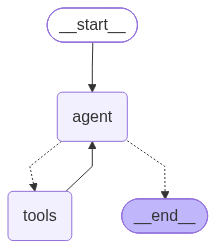

In [24]:
try:
    # Render the graph as a PNG (via the online Mermaid service), save it and display it
    display(Image(research_agent.get_graph().draw_mermaid_png(
        output_file_path="research-agent.png", max_retries=5, retry_delay=2.0)))
except Exception as e:
    # Without network access the PNG cannot be rendered: print the Mermaid text definition instead
    print(f"Could not display graph: {e}")
    print(research_agent.get_graph().draw_mermaid())

## 3.3 Run the Agent and Capture its Trajectory

In [25]:
def ask_agent(question: str, max_steps: int = 20) -> dict:
    """Run the research agent on one question and return the answer with its trajectory."""
    start_time = time.time()
    try:
        # Start the graph with the question as the only message. recursion_limit caps the number of
        # node executions (each tool round is 2 steps), so a looping agent stops instead of running forever.
        final_state = research_agent.invoke(
            {"messages": [HumanMessage(content=question)]},
            {"recursion_limit": max_steps},
        )
        # The final state holds the whole conversation; its last message is the final answer
        messages = final_state["messages"]
        answer, error = messages[-1].content, None
    except Exception as exc:                       # for example, the step limit was reached
        # Record the failure instead of crashing, so a batch of questions keeps running
        messages, answer, error = [], f"Agent failed: {exc}", str(exc)

    # The trajectory: every tool call, and the evidence every tool returned
    tools_called = []
    contexts = []
    for message in messages:
        # Only AIMessages have tool_calls; getattr returns None for the other message types
        for tool_call in getattr(message, "tool_calls", None) or []:
            tools_called.append({"name": tool_call["name"], "args": tool_call["args"]})
        if isinstance(message, ToolMessage):
            # PDF results are chunks joined by "---" lines:
            # split them so each chunk is one entry. A web result has no separator and stays one entry.
            contexts.extend(message.content.split("\n\n---\n\n"))

    return {
        "question": question,
        "answer": answer,
        "tools_called": tools_called,
        "contexts": contexts,
        "latency_s": round(time.time() - start_time, 1),
        "error": error,
    }


def print_trajectory(result: dict):
    """Print the tool calls and the final answer of one run."""
    print("QUESTION:", result["question"])
    # Number the steps from 1 so the order of the tool calls is easy to follow
    for step, tool_call in enumerate(result["tools_called"], start=1):
        print(f"  Step {step}: {tool_call['name']} {tool_call['args']}")
    print(f"ANSWER ({result['latency_s']}s):\n{result['answer']}")

The following code runs the agent on a question that needs **both** tools: Tesla's revenue is in the documents, and Ford is not in the corpus. A good trajectory shows a `pdf_search_tool` call for Tesla, a `tavily_web_search_tool` call for Ford, and an answer that cites a document for the first figure and a URL for the second.

In [26]:
# A question that needs both tools: Tesla's figure from the documents, Ford's from the web
sample_result = ask_agent("Compare Tesla's Q2 2026 total revenues with Ford's Q2 2026 revenues.")
print_trajectory(sample_result)

QUESTION: Compare Tesla's Q2 2026 total revenues with Ford's Q2 2026 revenues.
  Step 1: pdf_search_tool {'query': 'Tesla total revenue Q2 2026'}
  Step 2: tavily_web_search_tool {'query': 'Ford total revenue Q2 2026'}
ANSWER (11.4s):
In Q2 2026, Tesla reported total revenues of **$28.24 billion** [Source: tsla-20260630.pdf; p. 35]. In comparison, Ford's total revenues for the same quarter were **$48.3 billion** [Source: https://s205.q4cdn.com/882619693/files/doc_financials/2026/q2/Ford-Motor-Company-Q2-2026-Press-Release.pdf].

To summarize:
- **Tesla Q2 2026 Revenues:** $28.24 billion
- **Ford Q2 2026 Revenues:** $48.3 billion


## 3.4 Naive RAG Baseline

To know whether the agent's extra complexity is worth it, we need something to compare it against. The **naive RAG baseline** is the simplest system that can answer questions from the same documents. It works in two fixed steps:

1. **Retrieve**: search the vector store once, using the question itself as the query, and take the top 6 chunks.
2. **Generate**: send those chunks and the question to the LLM in a single call, asking it to answer only from the context and to cite its sources.

There is no loop and no decision-making: the baseline cannot search the web, rephrase a query that returned the wrong chunks, run a second search, or check its answer. Whatever the single retrieval returns is all the LLM ever sees.

To make the comparison fair, the baseline uses the **same retriever, the same LLM and the same `[Source: ...]` labels** as the agent, and the same citation format. The only difference between the two systems is the agentic behaviour.

`naive_rag` returns a dictionary with the same keys as `ask_agent`, so the evaluation code in Section 5 can treat both systems identically. Its `tools_called` always contains one `pdf_search_tool` entry: the baseline does not actually call the tool, but recording its single retrieval in the same format lets the tool check in Section 5 score both systems the same way. It has no `error` key; Section 5 reads it with `result.get("error")`, which returns `None` when the key is missing.

In [27]:
NAIVE_RAG_PROMPT = PromptTemplate.from_template("""
You are a market-competitor intelligence analyst at Allied FinServ. Answer the question using ONLY the context provided below.

Rules:
- Use only information found in the context; do not use outside knowledge.
- Copy figures exactly as they appear, with their units and period.
- Cite every figure with the file name and page from the passage's [Source: ...] label, in the format [file_name, p.N], for example [tsla-20260630.pdf, p.14].
- If the context does not contain the answer, say clearly that the information is not available.

CONTEXT:
{context}

QUESTION: {question}
""")

In [28]:
def naive_rag(question: str) -> dict:
    """Retrieve once from the vector store and answer with a single LLM call."""
    start_time = time.time()

    # Step 1 - Retrieve: one search with the question as the query, using the same retriever as the agent
    documents = retriever.invoke(question)

    # Label each chunk with [Source: file; page: N] using the same template as the PDF search tool (2.2.2),
    # so the baseline sees exactly the same format as the agent
    contexts = [format_document(document, document_prompt) for document in documents]

    # Step 2 - Generate: put the labelled chunks and the question into the prompt and make one LLM call
    prompt = NAIVE_RAG_PROMPT.format(context="\n\n---\n\n".join(contexts), question=question)
    answer = llm.invoke(prompt).content

    # Same keys as ask_agent, so Section 5 can evaluate both systems with the same code.
    # tools_called records the single retrieval in the agent's format.
    return {
        "question": question,
        "answer": answer,
        "tools_called": [{"name": "pdf_search_tool", "args": {"query": question}}],
        "contexts": contexts,
        "latency_s": round(time.time() - start_time, 1),
    }

## 3.5 First Comparison

Before the full evaluation in Section 5, a quick side-by-side comparison shows how the two systems behave. The following code runs both on three questions, each chosen to test a different capability:

| Question | What it needs | What to expect |
| --- | --- | --- |
| Tesla's free cash flow in Q2 2026 | The documents only | Both systems can answer from the Update deck |
| The latest news about Tesla's Robotaxi service | The web only | Only the agent can answer; naive RAG can only search the filings |
| Tesla's Q2 2026 deliveries vs BYD's BEV sales | Both sources | Only the agent can combine a document figure with a web figure |

For each question, the answers are displayed one under the other, with the agent's number of tool calls and the time each system took.

The answers are displayed as Markdown so that bold text and lists render. Dollar signs are escaped first: Jupyter treats text between two `$` signs as a LaTeX formula, so an answer that mentions two dollar amounts would otherwise be rendered as mathematics.

In [29]:
# Three questions, each testing a different capability: documents only, web only, and both
comparison_questions = [
    "What was Tesla's free cash flow in Q2 2026?",
    "What is the latest news about Tesla's Robotaxi service?",
    "How did Tesla's Q2 2026 deliveries compare with BYD's battery-electric vehicle sales in the same quarter?",
]

for question in comparison_questions:
    # Run both systems on the same question
    agent_result = ask_agent(question)
    rag_result = naive_rag(question)

    # Build one Markdown block per question: the agent's answer with its tool calls and time,
    # then the baseline's answer with its time
    text = (
        f"### {question}\n\n"
        f"**Research agent** ({len(agent_result['tools_called'])} tool calls, {agent_result['latency_s']}s):\n\n"
        f"{agent_result['answer']}\n\n"
        f"**Naive RAG** ({rag_result['latency_s']}s):\n\n{rag_result['answer']}\n\n---"
    )

    # Escape $ so that dollar amounts are not rendered as LaTeX math, then display the block
    display(Markdown(text.replace("$", r"\$")))

### What was Tesla's free cash flow in Q2 2026?

**Research agent** (1 tool calls, 5.4s):

Tesla's free cash flow for Q2 2026 was negative \$1.1 billion [Source: TSLA-Q2-2026-Update.pdf; page: 4].

**Naive RAG** (1.4s):

The information is not available.

---

### What is the latest news about Tesla's Robotaxi service?

**Research agent** (1 tool calls, 6.6s):

Recent developments regarding Tesla's Robotaxi service include significant fleet expansions and operational enhancements:

1. **Fleet Expansion**: Tesla has reported an impressive increase in its Robotaxi fleet in Austin, Texas, with the number of Cybercabs expanding to over 300, marking an eightfold increase in just 30 days. This expansion was highlighted by Elon Musk, who noted that the service is scaling rapidly [Source: https://finance.yahoo.com/technology/ai/articles/tesla-robotaxi-fleet-austin-soars-213024117.html].

2. **Extended Operating Hours**: The operating hours for the Robotaxi service have been extended from 10:00 PM to 11:00 PM, allowing for more service availability. However, challenges remain, particularly with nighttime visibility, which Musk cited as a concern due to low-contrast pets on dark pavements [Source: https://www.motor1.com/news/810873/tesla-robotaxi-nighttime-visibility-limits].

3. **Upcoming Software Update**: Tesla plans to release Full Self-Driving (FSD) version 15 in October 2026, which is expected to enhance the Robotaxi service significantly. This update will introduce a more advanced neural network, potentially enabling 24/7 service hours [Source: https://www.notateslaapp.com/news/4748/teslas-active-robotaxi-markets-and-their-sizes].

4. **New Charging Solutions**: Tesla has also unveiled a new autonomous charging solution for its Cybercab fleet, aimed at facilitating self-charging without human intervention. This is seen as a critical step towards achieving a fully autonomous, driverless service [Source: https://www.basenor.com/blogs/news/tesla-robotaxi-charging-4-details-that-matter].

These advancements indicate Tesla's commitment to rapidly scaling its Robotaxi service while addressing operational challenges.

**Naive RAG** (2.4s):

Tesla has started production of Cybercab, a purpose-built autonomous EV designed for its Robotaxi fleet. Engineering test drives of production Cybercabs on public roads began during the quarter, and employee rides in Cybercabs were offered on the Gigafactory Texas campus in July 2026. The company expanded the unsupervised operation area in Austin and launched unsupervised rides in Miami, Orlando, and Tampa in July 2026. Additionally, preparations for expanding the Robotaxi service to more U.S. metros are ongoing, which includes testing, permitting, and first responder training [TSLA-Q2-2026-Update.pdf, p. 9].

---

### How did Tesla's Q2 2026 deliveries compare with BYD's battery-electric vehicle sales in the same quarter?

**Research agent** (2 tool calls, 6.3s):

In Q2 2026, Tesla delivered a total of **480,126** battery-electric vehicles (BEVs) [Source: TSLA-Q2-2026-Update.pdf; page: 5]. In contrast, BYD reported sales of **557,090** battery-electric passenger vehicles during the same quarter [Source: https://electriccarsreport.com/2026/07/byd-overtakes-tesla-again-in-q2-2026-ev-sales-as-global-gap-widens]. 

This results in a difference of **76,964** units, with BYD leading Tesla by approximately **16%** in BEV sales for that quarter.

**Naive RAG** (1.4s):

The information is not available.

---

# **4. Generate the Market Intelligence Report**

**Observations**

- **Documents only (free cash flow):** In a single tool call, the agent answered correctly — Tesla's Q2 2026
  free cash flow was −$1.1 billion [TSLA-Q2-2026-Update.pdf, p.4]. "Not available," was the response from
  the naive RAG baseline. Even though this figure is in the documents,
  the baseline's one fixed search missed the right chunk, while the agent phrased an effective
  query and found it. Lesson: a good query matters, and the agent can craft one.

- **Web only (Robotaxi news):** Only the agent gave *current* news — fleet growth to 300+
  Cybercabs, new operating hours, and an NHTSA audit — each cited to a live URL. Due to the baseline
  only being able to  search the filings, it returned older Q2-filing text about the Robotaxi rollout,
  not the latest developments. For anything recent, document-only RAG is stale by design.

- **Both sources (Tesla vs BYD):** Only the agent combined a document figure with a web figure —
  Tesla's 480,126 deliveries [TSLA-Q2-2026-Update.pdf, p.5] vs BYD's 557,090 BEV sales [web] —
  and computed the ~16% gap. The baseline returned "not available" because it cannot search the web.

**Overall:** The agent was slower and used more calls (~6–10s, up to 2 tools, vs ~1–2s for the
baseline), but it answered all three correctly while the baseline answered only one well. The extra
time buys accuracy, current information, and multi-source synthesis — exactly what a reliable
intelligence report needs.


## 4.1 Generate the Report

The following code sends the research agent a detailed report request. The request fixes the structure, so every report has the same sections and can be reviewed consistently:

1. Executive Summary
2. Financial Performance
3. Competitive Landscape
4. Recent Developments
5. SWOT Analysis
6. Key Risks to Watch
7. Sources


In [30]:
# The company the report is about; it is also used in the output file names (4.3)
COMPANY_NAME = "Tesla"

# The report request becomes the agent's question. The system prompt from 3.1 still applies,
# so the routing, grounding and citation rules hold for the whole report.
REPORT_REQUEST = f"""
Write a competitive intelligence report on {COMPANY_NAME} for Allied FinServ, covering its Q2 2026 performance and its competitive position in electric vehicles and energy storage. Use the seven sections below, in this order. Use headings and bullet points only - no tables. Every figure must include its period and a citation: [file_name, p.N] for documents, or the full https:// URL for web sources.

1. Executive Summary
   - 3 to 4 sentences summarising {COMPANY_NAME}'s Q2 2026 results and competitive position.

2. Financial Performance
   - Use the Tesla Q2 2026 Update deck (TSLA-Q2-2026-Update.pdf) for these six metrics: total revenues, GAAP gross margin, GAAP net income, free cash flow, vehicle deliveries, and energy storage deployed.
   - For each metric, give the Q2 2026 value and compare it with the same quarter a year earlier (Q2 2025).
   - Use quarterly (three-month) figures only; do not use six-month (first-half) figures.

3. Competitive Landscape
   - Compare {COMPANY_NAME} with BYD, Rivian and Ford.
   - Run one web search per competitor, naming the company and the quarter (Q2 2026).
   - If no sourced figure is found for a competitor, write "no sourced figure" instead of guessing.

4. Recent Developments
   - 3 to 5 bullets on the latest news (product launches, Robotaxi, regulation), each cited to a web URL.

5. SWOT Analysis
   - Strengths, Weaknesses, Opportunities and Threats, with 2 bullets per category.

6. Key Risks to Watch
   - 3 to 5 bullets on the main risks to {COMPANY_NAME}, each tied to evidence.

7. Sources
   - List every document and URL cited above.
"""

In [31]:
# Run the same agent as in Section 3. A report needs many searches, so the step limit is raised
# from 20 to 50
report_result = ask_agent(REPORT_REQUEST, max_steps=50)

# A quick summary of the run: how much research the agent did and how long it took
print(f"Tool calls: {len(report_result['tools_called'])} | Time: {report_result['latency_s']}s")

Tool calls: 10 | Time: 24.9s


## 4.2 Display the Report

The following code renders the report as formatted Markdown. Dollar signs are escaped first: Jupyter treats text between two `$` signs as a LaTeX formula, so a line that mentions two dollar amounts would otherwise be displayed as mathematics. If the agent failed, the code prints the error and its last tool calls instead, to help diagnose the failure.

In [32]:
# ask_agent returns an answer starting with "Agent failed" when the run did not complete
if not report_result["answer"].startswith("Agent failed"):
    # Render the report. Escape $ so Jupyter does not display dollar amounts as LaTeX math.
    display(Markdown(report_result["answer"].replace("$", r"\$")))
else:
    # Show what went wrong, and the last tool calls the agent made
    print("Error:", report_result["answer"])
    print("Last tool calls:", report_result["tools_called"][-3:])

# Competitive Intelligence Report on Tesla

## 1. Executive Summary
In Q2 2026, Tesla reported total revenues of \$28.24 billion, a significant increase from the previous year, driven by strong vehicle deliveries and energy storage deployments. However, net income decreased slightly to \$1.11 billion, reflecting ongoing investments in production capacity and technology. Tesla continues to lead the electric vehicle market, but faces increasing competition from companies like BYD, Rivian, and Ford, each making strides in their respective segments.

## 2. Financial Performance
- **Total Revenues**: \$28.24 billion in Q2 2026, up from \$22.50 billion in Q2 2025 [TSLA-Q2-2026-Update.pdf, p. 4].
- **GAAP Gross Margin**: 16.8% in Q2 2026, down from 17.2% in Q2 2025 [TSLA-Q2-2026-Update.pdf, p. 4].
- **GAAP Net Income**: \$1.11 billion in Q2 2026, compared to \$1.17 billion in Q2 2025 [tsla-20260630.pdf, p. 14].
- **Free Cash Flow**: Negative \$1.09 billion in Q2 2026, down from positive \$0.15 billion in Q2 2025 [TSLA-Q2-2026-Update.pdf, p. 4].
- **Vehicle Deliveries**: 480,126 units in Q2 2026, up from 384,122 units in Q2 2025 [TSLA-Q2-2026-Update.pdf, p. 5].
- **Energy Storage Deployed**: 22.3 GWh in Q2 2026, compared to 9.6 GWh in Q2 2025 [tsla-20260630.pdf, p. 35].

## 3. Competitive Landscape
- **BYD**: Delivered 557,090 vehicles in Q2 2026, up from 606,993 in Q2 2025. Net profit was approximately \$1.22 billion [https://theevreport.com/ev-sales-monitor-q2-2026].
- **Rivian**: Reported automotive revenue of \$1.14 billion in Q2 2026, with a net loss of \$837 million [https://www.cnbc.com/2026/07/30/rivian-rivn-q2-2026-earnings.html].
- **Ford**: Achieved revenues of \$48.3 billion in Q2 2026, with a net loss of \$2.4 billion [https://s205.q4cdn.com/882619693/files/doc_financials/2026/q2/Ford-Motor-Company-Q2-2026-Press-Release.pdf].

## 4. Recent Developments
- Tesla unveiled its new Roadster, showcasing advanced capabilities including flight features [https://www.cbsnews.com/tag/tesla].
- The company launched the Cybercab and expanded its Robotaxi service to three cities in Florida [https://finance.yahoo.com/quote/TSLA/news].
- Tesla is investing over \$1 billion in a lithium refinery in Texas to enhance battery supply [https://www.tesla.com/blog].
- The rollout of FSD (Full Self-Driving) subscriptions continues to grow, with significant customer uptake [https://finance.yahoo.com/quote/TSLA/news].
- Tesla's energy storage deployments reached record levels, particularly in EMEA [https://finance.yahoo.com/quote/TSLA/news].

## 5. SWOT Analysis
- **Strengths**:
  - Strong brand recognition and market leadership in EVs.
  - Advanced technology in AI and autonomous driving.
- **Weaknesses**:
  - Recent decline in net income despite revenue growth.
  - High capital expenditures impacting free cash flow.
- **Opportunities**:
  - Expansion into new markets and product lines, including energy storage.
  - Increasing demand for sustainable energy solutions.
- **Threats**:
  - Intensifying competition from established automakers and new entrants.
  - Regulatory challenges and potential changes in EV incentives.

## 6. Key Risks to Watch
- Ongoing supply chain disruptions affecting production capacity.
- Fluctuations in raw material prices, particularly lithium and cobalt.
- Regulatory changes impacting EV incentives and market dynamics.
- Competition from rivals like BYD, Rivian, and Ford, which may erode market share.
- Potential legal challenges related to autonomous driving technology.

## 7. Sources
- Tesla Q2 2026 Update deck (TSLA-Q2-2026-Update.pdf)
- Tesla Form 10-Q, quarter ended June 30, 2026 (tsla-20260630.pdf)
- https://theevreport.com/ev-sales-monitor-q2-2026
- https://www.cnbc.com/2026/07/30/rivian-rivn-q2-2026-earnings.html
- https://s205.q4cdn.com/882619693/files/doc_financials/2026/q2/Ford-Motor-Company-Q2-2026-Press-Release.pdf
- https://www.cbsnews.com/tag/tesla
- https://finance.yahoo.com/quote/TSLA/news
- https://www.tesla.com/blog

## 4.3 Save the Report

The following code saves two files, both named with the company and today's date:

- `<company>_market_report_<YYYY-MM-DD>.md`: the report itself, as Markdown that renders on GitHub or in any Markdown editor (the `$` escape is only needed for display inside Jupyter, so the saved file keeps plain `$` signs).
- `<company>_market_report_<YYYY-MM-DD>_trajectory.json`: the full result of the run: the request, the answer, every tool call with its arguments, and the evidence every tool returned.

The trajectory file is an **audit trail**: a reviewer can trace each figure in the report back to the tool result it came from, without re-running the agent. It is saved even if the agent failed; the report file is saved only when the run succeeded.

In [33]:
# File names include the company and today's date, e.g. Tesla_market_report_2026-10-05.md
file_date = datetime.now().strftime("%Y-%m-%d")
report_file = f"{COMPANY_NAME}_market_report_{file_date}.md"
trajectory_file = f"{COMPANY_NAME}_market_report_{file_date}_trajectory.json"

# Always save the trajectory: the request, answer, tool calls, evidence, latency and any error.
# indent=2 makes the JSON readable for a human reviewer.
with open(trajectory_file, "w", encoding="utf-8") as file:
    json.dump(report_result, file, indent=2)

if report_result.get("error"):
    # Do not save an error message as if it were a report
    print("Report not saved because the agent failed:", report_result["error"])
    print("Trajectory saved for debugging:", trajectory_file)
else:
    # Save the report as written by the agent, with plain $ signs (the escape is only for Jupyter display)
    with open(report_file, "w", encoding="utf-8") as file:
        file.write(report_result["answer"])
    print("Files saved:", report_file, "and", trajectory_file)

Files saved: Tesla_market_report_2026-10-18.md and Tesla_market_report_2026-10-18_trajectory.json


# **5. Agentic Evaluation**

A report that looks professional can still contain wrong or unsupported figures, as Section 4 showed. Reading a few answers is not enough to know how reliable a system is. We need to test it on many questions whose correct answers are known, and measure the results.

In this section we evaluate the research agent and the naive RAG baseline on the same **golden dataset**, in two complementary ways:

- **Deterministic checks**: plain Python code that compares each output with the known answer, for example "does the answer contain the figure `28,236`?". These checks are fast, free and give the same result every time, but they only see what they are told to look for.
- **LLM-as-a-judge**: a separate, stronger LLM reads each answer and grades it against the expected answer. It understands meaning, so it can tell whether a figure belongs to the right period or whether an open-ended answer actually answers the question. It costs one LLM call per answer and, being a model, can itself be wrong, so its verdicts are checked too.

The checks are grouped by the **layer** of the system they test:

| Layer | Check | Question it answers |
| --- | --- | --- |
| Tool use | `tools_ok` | Did the system call every tool the question needs? |
| Tool use | `num_tool_calls` | How many tool calls did it make? |
| Retrieval | `evidence_ok` | Does the retrieved evidence contain the gold figure? |
| Answer | `figure_ok` | Does the answer contain the gold figure? |
| Answer | `cites_file`, `cites_url` | Does the answer cite the expected document, or a web source? |
| Answer | `refused` | For undisclosed information, does the answer say it is not available? |
| Answer | `judge_verdict`, `judge_score` | Does the LLM judge rate the answer as correct against the expected answer? |
| Efficiency | `latency_s` | How long did the answer take? |

Grouping the checks by layer is what makes the evaluation useful for improving the system. When an answer is wrong, the layers show *where* it went wrong: a missing tool call, evidence that never reached the agent, or a mistake in writing the answer from good evidence. Each cause has a different fix.

## 5.1 Load the Golden Dataset

A **golden** is a test question together with its expected answer or expected behaviour. The golden dataset in `data/golden_dataset.csv` contains 24 hand-written cases in five categories. Each category targets a different capability or a known weak spot:

| Category | Cases | What it tests | Expected tools |
| --- | --- | --- | --- |
| `pdf_factual` | 12 | A figure that is in the documents, including one Tesla vs Rivian comparison across two filings | `pdf_search_tool` |
| `conflict` | 3 | Figures that differ by date (for example December 2025 vs June 2026, or Q1 vs Q2 2026): the system must report the latest one | `pdf_search_tool` |
| `hybrid` | 3 | A comparison with a company that is not in the documents (Ford, BYD), or a document figure combined with recent news | both tools |
| `web_current` | 3 | Recent news or market data that is not in the documents | `tavily_web_search_tool` |
| `unanswerable` | 3 | Information that Tesla does not disclose: the system must say so instead of inventing a figure | the system must say it is not available |

Each row contains:

- `id`, `category` and `question`
- `expected_tools` - the tools a good answer needs, separated by `;`
- `expected_output` - the expected answer, or a description of the expected behaviour (used by the LLM judge)
- `expected_value` and `value_unit` - the gold figure for numeric questions. Monetary values are stored in U.S. dollars, so `28236000000` means $28,236 million.
- `expected_source` - the file or files that contain the gold figure, separated by `|`

Web answers change over time, so `web_current` cases have no fixed gold figure. They are graded on behaviour instead: the web search tool must be called and a URL must be cited, and the LLM judge checks that the answer is specific and recent.

The checks match on the file names in `expected_source`, so do not rename the PDFs in the `data` folder.

In [34]:
# Load the golden dataset (extracted from data.zip in Section 2.2.1)
golden_dataset = pd.read_csv("data/golden_dataset.csv")

# pandas reads empty cells as NaN (a float). These three columns are split on ";" or "|" later,
# which fails on NaN, so empty cells are replaced with an empty string.
# expected_value is left as NaN on purpose: the checks use pd.isna() to detect "no gold figure".
text_columns = ["expected_tools", "expected_source", "value_unit"]
golden_dataset[text_columns] = golden_dataset[text_columns].fillna("")

In [35]:
# Number of questions in each category
print(golden_dataset["category"].value_counts())

category
pdf_factual     12
conflict         3
hybrid           3
web_current      3
unanswerable     3
Name: count, dtype: int64


In [36]:
# Show the first rows to see the structure of a golden
golden_dataset.head(5)

,id,category,question,expected_tools,expected_output,expected_value,value_unit,expected_source
0,gold_01,pdf_factual,What were Tesla's total revenues in Q2 2026?,pdf_search_tool,"Tesla's total revenues were $28,236 million in...",2.823600e+10,USD,tsla-20260630.pdf|TSLA-Q2-2026-Update.pdf
1,gold_02,pdf_factual,What was Tesla's total GAAP gross margin in Q2...,pdf_search_tool,Tesla's total GAAP gross margin was 16.8% in Q...,1.680000e+01,percent,TSLA-Q2-2026-Update.pdf
2,gold_03,pdf_factual,How many vehicles did Tesla deliver in Q2 2026?,pdf_search_tool,"Tesla delivered 480,126 vehicles in Q2 2026 (4...",4.801260e+05,count,TSLA-Q2-2026-Update.pdf
3,gold_04,pdf_factual,What was Tesla's free cash flow in Q2 2026?,pdf_search_tool,"Tesla's free cash flow was negative $1,092 mil...",-1.092000e+09,USD,TSLA-Q2-2026-Update.pdf
4,gold_05,pdf_factual,How much energy storage did Tesla deploy in Q2...,pdf_search_tool,Tesla deployed 13.5 GWh of energy storage in Q...,1.350000e+01,GWh,TSLA-Q2-2026-Update.pdf


## 5.2 Run Both Systems on the Golden Dataset

The following code runs **both** systems on every question in the golden dataset and keeps each full result: the answer, the tool calls, the retrieved evidence and the latency. Nothing is graded yet. Running the systems once and storing the results means the checks in 5.3 to 5.6 can be run, changed and re-run without calling the agent again.

This is the slowest step of the evaluation: 24 questions × 2 systems, and the agent may call several tools per question. Expect a few minutes. The question being processed is printed so you can follow progress.

In [37]:
# One result dictionary per question for each system, in the same order as golden_dataset,
# so result number i always belongs to golden question number i
agent_results = []
rag_results = []

for _, row in golden_dataset.iterrows():
    # Show progress: which question is being answered
    print(f"{row['id']} ({row['category']}): {row['question']}")

    # Ask the same question to both systems. Each returns a dictionary with
    # answer, tools_called, contexts and latency_s (ask_agent also returns error).
    agent_results.append(ask_agent(row["question"]))
    rag_results.append(naive_rag(row["question"]))

print("--- All questions answered ---")

gold_01 (pdf_factual): What were Tesla's total revenues in Q2 2026?


gold_02 (pdf_factual): What was Tesla's total GAAP gross margin in Q2 2026?


gold_03 (pdf_factual): How many vehicles did Tesla deliver in Q2 2026?


gold_04 (pdf_factual): What was Tesla's free cash flow in Q2 2026?


gold_05 (pdf_factual): How much energy storage did Tesla deploy in Q2 2026?


gold_06 (pdf_factual): What were Tesla's total revenues for fiscal year 2025?


... (15 outputs left out)

gold_22 (unanswerable): What gross margin did Tesla earn on the Cybertruck alone in Q2 2026?


gold_23 (unanswerable): What is Tesla's internal research and development budget for the year 2030?


gold_24 (unanswerable): How much revenue did Tesla's Berlin factory generate in Q2 2026?


--- All questions answered ---


## 5.3 Answer Checks

The first group of deterministic checks looks only at the **answer** text. `answer_checks` takes one answer and its golden row, and returns four checks:

- **`figure_ok`** (questions with an `expected_value`): does the gold figure appear in the answer? The CSV stores values in a uniform format (for example `28236000000` for $28,236 million), but the documents print them differently. `gold_figure` converts the stored value into the printed form: `28,236` (dollar amounts, in millions), `16.8%` (percentages), `13.5` (GWh) or `480,126` (counts). The check is then a simple text search. It works because the system prompt tells the agent to copy figures exactly as printed.

  The check is deliberately **strict**. Tesla's December 2025 cash and investments (`44,059`) and its June 2026 figure (`43,524`) are different strings, so an out-of-date value fails, which is exactly what the `conflict` questions test. The price of strictness: a rounded answer such as "$1.1 billion" for `$1,092 million` also fails. The LLM judge in Section 5.5 decides whether such an answer is acceptable.
- **`cites_file`**: does the answer cite one of the files that contain the gold figure?
- **`cites_url`**: does the answer cite a web source (any `http` address)?
- **`refused`** (`unanswerable` questions only): does the answer contain a refusal phrase such as "not disclosed" or "not available"? This is a simple keyword check: an answer can say "not disclosed" and still go on to give an invented figure. The LLM judge reads the whole answer and catches that case.

A check that does not apply to a question returns `None`, not `False`. For example, `figure_ok` is `None` for a news question with no gold figure. This matters in the scorecard (5.6): `None` is left out of the averages instead of counting as a failure.

The answer is converted to lower case before the checks, because the agent may change the case of a file name such as `TSLA-Q2-2026-Update.pdf`.

In [38]:
# Phrases that signal the system declined to give a figure (in lower case, because the answer is lowered)
REFUSAL_PHRASES = ["not available", "not disclosed", "does not disclose", "not separately disclosed",
                   "does not break out", "not reported"]


def gold_figure(row):
    """The gold figure as the documents print it, e.g. 28236000000 USD -> '28,236'. None if there is no figure."""
    value, unit = row["expected_value"], row["value_unit"]

    # No gold figure (news and undisclosed-information questions): the figure checks do not apply
    if pd.isna(value):
        return None

    if unit == "USD":
        # Stored in dollars, printed in millions with thousands separators: 28236000000 -> "28,236".
        # abs() drops the sign, because negatives are printed in brackets, e.g. (1,092).
        return f"{abs(value) / 1e6:,.0f}"
    if unit == "percent":
        return f"{value}%"                  # 16.8 -> "16.8%"
    if unit == "GWh":
        return f"{value}"                   # 13.5 -> "13.5"
    return f"{value:,.0f}"                  # counts, e.g. deliveries: 480126 -> "480,126"


def answer_checks(answer, row):
    """Check the answer: gold figure present, sources cited, undisclosed information refused."""
    # Compare in lower case: the agent may change the case of file names
    answer = answer.lower()
    gold = gold_figure(row)

    # expected_source may list several files separated by "|"; empty strings are skipped
    files = [name.lower() for name in row["expected_source"].split("|") if name]

    return {
        # Is the gold figure, as printed, anywhere in the answer? (None if there is no gold figure)
        "figure_ok": gold in answer if gold else None,
        # Does the answer name at least one of the expected source files? (None if no file is expected)
        "cites_file": any(name in answer for name in files) if files else None,
        # Does the answer contain a web address?
        "cites_url": "http" in answer,
        # For undisclosed information only: does the answer contain a refusal phrase?
        "refused": any(phrase in answer for phrase in REFUSAL_PHRASES) if row["category"] == "unanswerable" else None,
    }

Before running the checks on every answer, test them on hand-written answers whose result we know. The first answer is correct and cited, so `figure_ok` and `cites_file` should be `True`. The second gives the out-of-date figure for a different period, so `figure_ok` should be `False`.

In [39]:
# A minimal golden row with just the fields answer_checks needs
test_row = {"expected_value": 28236e6, "value_unit": "USD", "expected_source": "tsla-20260630.pdf",
            "category": "pdf_factual"}

# Correct figure with a citation -> figure_ok True, cites_file True
print(answer_checks("Q2 2026 total revenues were $28,236 million [tsla-20260630.pdf, p.7].", test_row))

# Wrong figure (Q2 2025 revenues), no citation -> figure_ok False, cites_file False
print(answer_checks("Q2 2026 total revenues were $22,496 million.", test_row))

{'figure_ok': True, 'cites_file': True, 'cites_url': False, 'refused': None}
{'figure_ok': False, 'cites_file': False, 'cites_url': False, 'refused': None}


## 5.4 Evidence and Tool Checks

The second group of checks looks at the **trajectory**: the tool calls the system made and the evidence they returned. These checks explain *why* an answer is right or wrong.

- **`tools_ok`**: was every expected tool called at least once? A web question answered without the web search tool, for example, fails here. Extra tool calls are not penalised; `num_tool_calls` records how many calls were made, which shows how much work each answer cost.
- **`evidence_ok`**: does the gold figure appear anywhere in the evidence the tools returned? If it does not, the figure never reached the LLM, so the system could not have answered correctly, whatever the LLM did next. Comparing `evidence_ok` with `figure_ok` separates two very different failures:
  - `evidence_ok = False`: a **retrieval** problem; the search never found the figure.
  - `evidence_ok = True` but `figure_ok = False`: a **synthesis** problem; the figure was found but the answer got it wrong.

The second cell runs both groups of checks on every answer of both systems and collects the results in one table, `results_df`, with one row per (system, golden question). The table also keeps each question, expected output, answer and list of tool calls, so the judge (5.5) and the failure analysis (5.6) can read everything they need from this one table.

Finally, each answer gets an overall deterministic verdict, `passed`, from the checks that fit its category:

| Category | Passes when |
| --- | --- |
| `pdf_factual`, `conflict` | the gold figure is in the answer and the expected file is cited |
| `hybrid` | the gold figure (Tesla's part) is in the answer and a web source is cited for the competitor |
| `web_current` | the web search tool was called and a web source is cited |
| `unanswerable` | the answer says the information is not available |

In [40]:
def evidence_checks(result, row):
    """Check the trajectory: expected tools called, gold figure present in the retrieved evidence."""
    # The set of tools the system actually called (a set, so repeated calls count once)
    called = {call["name"] for call in result["tools_called"]}

    # The set of tools the question needs; empty strings are skipped
    expected = {name for name in row["expected_tools"].split(";") if name}

    gold = gold_figure(row)
    return {
        # issubset: every expected tool is among the called tools (extra tools are allowed)
        "tools_ok": expected.issubset(called),
        # Join all retrieved chunks and web results into one text and search it for the gold figure
        "evidence_ok": gold in "\n".join(result["contexts"]) if gold else None,
        # How many tool calls the system made in total, repeats included
        "num_tool_calls": len(result["tools_called"]),
    }

In [41]:
# One row per (system, golden question): the answer, the trajectory and every check
rows = []
for system, results in [("agent", agent_results), ("naive_rag", rag_results)]:
    # The results lists were built in the same order as golden_dataset (5.2), so zip pairs
    # each golden question with that system's result for it
    for (_, golden), result in zip(golden_dataset.iterrows(), results):
        rows.append({
            "system": system,
            "id": golden["id"],
            "category": golden["category"],
            # Kept for the judge (5.5) and the failure analysis (5.6)
            "question": golden["question"],
            "expected_output": golden["expected_output"],
            "answer": result["answer"],
            "tools_called": result["tools_called"],
            # ** unpacks each returned dictionary into separate columns:
            # figure_ok, cites_file, cites_url, refused, tools_ok, evidence_ok, num_tool_calls
            **answer_checks(result["answer"], golden),
            **evidence_checks(result, golden),
            "latency_s": result["latency_s"],
            # naive_rag has no "error" key; .get() returns None for it
            "error": result.get("error"),
        })

results_df = pd.DataFrame(rows)


def passed(row):
    """Overall deterministic verdict, using the checks that fit the question category."""
    # bool() turns None (check not applicable) into False, so a missing required check fails
    if row["category"] == "unanswerable":
        return bool(row["refused"])
    if row["category"] == "web_current":
        return bool(row["tools_ok"] and row["cites_url"])
    if row["category"] == "hybrid":
        return bool(row["figure_ok"] and row["cites_url"])
    return bool(row["figure_ok"] and row["cites_file"])        # pdf_factual and conflict


# Apply passed() to every row (axis=1 means row by row) and store the verdict as a new column
results_df["passed"] = results_df.apply(passed, axis=1)

# Show the checks for the first 10 rows (the agent's answers); the text columns are left out for readability
results_df[["system", "id", "category", "passed", "figure_ok", "cites_file", "cites_url",
            "refused", "tools_ok", "evidence_ok", "num_tool_calls"]].head(10)

,system,id,category,passed,figure_ok,cites_file,cites_url,refused,tools_ok,evidence_ok,num_tool_calls
0,agent,gold_01,pdf_factual,True,True,True,False,None,True,True,1
1,agent,gold_02,pdf_factual,False,False,False,False,None,True,True,1
2,agent,gold_03,pdf_factual,False,True,False,False,None,True,True,1
3,agent,gold_04,pdf_factual,False,False,True,False,None,True,True,1
4,agent,gold_05,pdf_factual,False,False,False,False,None,True,False,1
5,agent,gold_06,pdf_factual,False,False,True,False,None,True,True,1
6,agent,gold_07,pdf_factual,True,True,True,False,None,True,True,1
7,agent,gold_08,pdf_factual,True,True,True,False,None,True,False,1
8,agent,gold_09,pdf_factual,False,False,False,True,None,False,False,1
9,agent,gold_10,pdf_factual,True,True,True,False,None,True,True,1


## 5.5 LLM-as-a-Judge: Answer Correctness

The deterministic checks are precise but narrow. `figure_ok` only checks that the gold figure appears *somewhere* in the answer, so it cannot tell whether:

- the figure is given for the right period (an answer that swaps the June 2026 and December 2025 cash figures still contains `43,524`),
- a `conflict` answer says which value is the latest,
- a `hybrid` answer actually adds the competitor's figure or the news from the web,
- a `web_current` answer actually answers the question, rather than just citing a URL.

These are questions about **meaning**, which code cannot check but an LLM can. An **LLM judge** reads the whole answer and compares it with the expected answer (`expected_output`) from the golden dataset. It returns a short `reasoning` followed by a `verdict`, which is converted into a score:

| Verdict | Meaning | `judge_score` |
| --- | --- | --- |
| `correct` | The answer gives the information in the expected answer, with no errors | 1.0 |
| `partially_correct` | The main figure or conclusion is right, but a required part is missing | 0.5 |
| `incorrect` | The main figure or conclusion is wrong or missing, or the answer invents information | 0.0 |

Design choices that make the judge more reliable:

- **A separate, stronger judge model**: `JUDGE_MODEL` (gpt-4o) grades the answers written by gpt-4o-mini, at temperature 0. A model grading its own answers tends to be lenient with them.
- **A reference answer**: the judge compares the answer with `expected_output` instead of relying on its own knowledge, which does not cover Q2 2026.
- **Today's date and a rule per category**: for example, a `conflict` answer must report the latest value with its date, and a `web_current` answer must give recent information with web sources. Only the rule for the question's category is inserted into the prompt.
- **Reasoning before the verdict**: the `reasoning` field comes first, so the judge compares the figures before it commits to a verdict.
- **Structured output**: `with_structured_output` and a Pydantic model force every response into the same two fields, so no verdict has to be parsed out of free text.

The judge checks **correctness against the expected answer**. It does not see the retrieved evidence, so it does not check whether the answer is supported by its sources; the citation and evidence checks cover that.

In [42]:
# The shape of every judge response. with_structured_output turns this class into a schema the
# model must fill in; the docstring and the field descriptions are sent to the model as instructions.
class JudgeVerdict(BaseModel):
    """The judge's assessment of one answer."""
    # Listed first, so the model writes its comparison before choosing a verdict
    reasoning: str = Field(description="Two or three sentences comparing the answer with the reference")
    # Literal restricts the verdict to exactly these three values
    verdict: Literal["correct", "partially_correct", "incorrect"]


# The grading instructions. The {placeholders} are filled in for each answer by judge_prompt() below.
JUDGE_PROMPT = PromptTemplate.from_template("""
You are a strict evaluator grading the correctness of an answer produced by a market-intelligence assistant. Today is {today}.

Compare the ANSWER with the REFERENCE and decide whether the ANSWER is correct. Grade the content only, not the style or the length.

This question is in the "{category}" category. Apply this category-specific rule: {category_rule}

General rules:
- A figure is correct only if its value, unit AND period match the reference.
- Rounding is acceptable (for example "$28.2 billion" for $28,236 million), but a different period or a different value is not.
- An invented figure, or one that contradicts the reference, makes the answer incorrect.
- Judge only the information actually written in the ANSWER; do not rely on outside knowledge.

Verdicts:
- "correct": the ANSWER gives the information in the REFERENCE, with no errors.
- "partially_correct": the main figure or conclusion is right, but a required part is missing.
- "incorrect": the main figure or conclusion is wrong or missing, or the ANSWER invents information.

QUESTION: {question}
REFERENCE: {reference}
ANSWER: {answer}
""")

In [43]:

# One extra grading rule per question category; only the matching rule is put into the prompt
CATEGORY_RULES = {
    "pdf_factual": "Give the reference figure for the right company and period.",
    "conflict": "The answer must give the most recent value with its date; giving only the older value is incorrect.",
    "hybrid": "The answer must give the document figure AND the web part (a competitor figure or recent news) with a web source. Web figures change over time, so a sourced figure that differs somewhat from the reference is acceptable. Without the web part, the answer is only partially_correct.",
    "web_current": "The reference describes expected behaviour, not a fixed answer. The answer is correct if it gives specific, recent information with web sources; an answer that only says the information is not available is incorrect.",
    "unanswerable": "Correct only if the answer says the information is not disclosed and gives no figure for it.",
}

# Verdict -> numeric score, so verdicts can be averaged in the scorecard
JUDGE_SCORES = {"correct": 1.0, "partially_correct": 0.5, "incorrect": 0.0}

# The judge model (gpt-4o, temperature 0, from Section 1.3), forced to return a JudgeVerdict object.
# method="function_calling" works with OpenAI and with most OpenAI-compatible gateways.
judge = judge_llm.with_structured_output(JudgeVerdict, method="function_calling")


def judge_prompt(row):
    """Build the judge prompt from a row that has category, question, expected_output and answer."""
    return JUDGE_PROMPT.format(
        today=current_date,                                # lets the judge decide what "recent" means
        category=row["category"],
        category_rule=CATEGORY_RULES[row["category"]],    # the rule for this question's category
        question=row["question"],
        reference=row["expected_output"],                  # the expected answer from the golden dataset
        answer=row["answer"],
    )

**Test the judge before trusting it.** Before grading every answer, run the judge on two answers whose correct verdict we know. Both contain the gold figure `43,524`, so `figure_ok` is `True` for both.

The second answer, however, swaps the dates of the two cash figures. The judge should grade the first `correct` and the second `incorrect`. This is exactly the kind of error the deterministic checks cannot see, and the reason the judge is needed.

In [44]:
# gold_13 is a conflict question: Tesla's cash, cash equivalents and investments (June 2026 vs December 2025)
cash_question = golden_dataset[golden_dataset["id"] == "gold_13"].iloc[0]

test_answers = [
    # Correct: the June 2026 figure is presented as the latest
    "Tesla's cash, cash equivalents and investments were $43,524 million at June 30, 2026, "
    "down from $44,059 million at December 31, 2025 [TSLA-Q2-2026-Update.pdf, p.4].",
    # Wrong: same two figures, but the dates are swapped
    "Tesla's cash, cash equivalents and investments were $44,059 million at June 30, 2026, "
    "up from $43,524 million at December 31, 2025 [TSLA-Q2-2026-Update.pdf, p.4].",
]

for answer in test_answers:
    # judge_prompt needs a row with an "answer" field: take the golden row and add the test answer.
    # The | operator merges two dictionaries.
    verdict = judge.invoke(judge_prompt(cash_question.to_dict() | {"answer": answer}))

    # Compare with the deterministic check: figure_ok is True for both answers
    figure_ok = answer_checks(answer, cash_question)["figure_ok"]
    print(f"figure_ok={figure_ok} | judge={verdict.verdict}\n  {verdict.reasoning}\n")

figure_ok=True | judge=correct
  The ANSWER provides the most recent figure of $43,524 million at the end of Q2 2026, which matches the REFERENCE. It also includes the earlier figure of $44,059 million at December 31, 2025, as required. Both the values and their respective dates are correctly reported, fulfilling the criteria for a correct answer in the 'conflict' category.



figure_ok=True | judge=incorrect
  The ANSWER incorrectly states the figures and their respective dates. It claims that the cash position was $44,059 million at June 30, 2026, and $43,524 million at December 31, 2025, which is the reverse of the correct information. According to the REFERENCE, the most recent figure is $43,524 million at the end of Q2 2026, and the earlier figure is $44,059 million at December 31, 2025. This reversal of figures and dates makes the ANSWER incorrect.



The following code grades every answer in `results_df`, for both systems (48 answers). `.batch` sends the requests in parallel, at most 5 at a time, which is much faster than one request after another while staying within API rate limits. `return_exceptions=True` keeps the run going if a request fails: that answer gets the verdict `error` and no score, instead of stopping the whole batch.

The final table counts the verdicts for each system: a first view of how the two compare.

In [45]:
# One prompt per row of results_df, in the same order as the table
prompts = [judge_prompt(row) for _, row in results_df.iterrows()]

# Send up to 5 requests at a time. With return_exceptions=True, a failed request returns the
# exception object in its place instead of stopping the batch.
verdicts = judge.batch(prompts, config={"max_concurrency": 5}, return_exceptions=True)

# Store the results as new columns. A successful response is a JudgeVerdict; anything else is an error.
results_df["judge_verdict"] = [v.verdict if isinstance(v, JudgeVerdict) else "error" for v in verdicts]
results_df["judge_reasoning"] = [v.reasoning if isinstance(v, JudgeVerdict) else str(v) for v in verdicts]

# Convert verdicts to scores; "error" is not in JUDGE_SCORES, so it becomes NaN and is skipped in averages
results_df["judge_score"] = results_df["judge_verdict"].map(JUDGE_SCORES)

# Count the verdicts per system: rows are systems, columns are verdicts
pd.crosstab(results_df["system"], results_df["judge_verdict"])

judge_verdict,correct,incorrect,partially_correct
system,,,
agent,19,4,1
naive_rag,10,10,4


## 5.6 Scorecard and Failure Analysis

All the checks are now in one table. This section turns them into conclusions in three steps: a **scorecard** that compares the two systems, a check of **how far the judge can be trusted**, and a **failure analysis** that explains why the agent's wrong answers went wrong.

The following code builds the **scorecard**: the average of every check for each system. True/False checks become rates (1.0 = 100%), and checks that do not apply to a question (`None`) are left out of its average instead of counting as failures. For example, the `refused` rate is computed over the three `unanswerable` questions only.

The second table breaks `passed` and `judge_score` down by question category. This shows *where* the agent adds value over naive RAG. Expect the biggest gap on `web_current` and `hybrid` questions, which naive RAG cannot answer because it has no web access.

In [46]:
# The checks to summarise, from both groups of deterministic checks, the judge and efficiency
metrics = ["passed", "judge_score", "figure_ok", "cites_file", "cites_url", "refused",
           "tools_ok", "evidence_ok", "num_tool_calls", "latency_s"]

# astype(float): True/False become 1.0/0.0, and None (check does not apply) becomes NaN, which mean() skips.
# groupby: one average per system. .T: transpose, so each metric is a row and each system a column.
scorecard = results_df[metrics].astype(float).groupby(results_df["system"]).mean().T.round(2)
display(scorecard)

# Pass rate and judge score per category and system: shows where the agent adds value
by_category = results_df.pivot_table(index="category",
                                     columns="system",
                                     values=["passed", "judge_score"], aggfunc="mean").round(2)
display(by_category)

system,agent,naive_rag
passed,0.50,0.42
judge_score,0.81,0.50
figure_ok,0.39,0.44
cites_file,0.67,0.72
cites_url,0.25,0.00
refused,1.00,1.00
tools_ok,0.88,0.75
evidence_ok,0.72,0.61
num_tool_calls,1.29,1.00
latency_s,3.67,1.60


judge_score           passed          
system             agent naive_rag  agent naive_rag
category                                           
conflict            0.67      0.33   0.00      0.00
hybrid              1.00      0.33   0.33      0.00
pdf_factual         0.75      0.58   0.42      0.58
unanswerable        1.00      1.00   1.00      1.00
web_current         0.83      0.00   1.00      0.00

**Can we trust the judge?** An LLM judge is a model too, and it can be wrong. Before relying on its verdicts, compare them with the deterministic `passed` verdict. The following code shows how often the two agree and lists every answer where they disagree.

Read these cases carefully: each disagreement points to a weakness in either the deterministic checks or the judge.

| Deterministic | Judge | Usual cause |
| --- | --- | --- |
| passed | not `correct` | The figure is in the answer but attached to the wrong period or date, or a required part is missing: the deterministic check is too lenient. Sometimes the judge is too strict. |
| failed | `correct` | The answer is right, but a deterministic check missed it, for example a rounded figure such as $1.1 billion, or a citation without the file name. Sometimes the judge is too lenient. |

For `web_current` questions the judge is the only check of the content, and for `unanswerable` questions it backs up the keyword-based refusal check.

In [47]:
# Treat only "correct" as a judge pass; partially_correct, incorrect and error count as not passed
judge_passed = results_df["judge_verdict"] == "correct"

# Share of answers where the judge and the deterministic checks reach the same pass/fail verdict
agreement = (judge_passed == results_df["passed"]).mean()
print(f"The judge agrees with the deterministic verdict on {agreement:.0%} of answers\n")

# Read every disagreement: each one points to a weakness in the checks or in the judge
for _, row in results_df[judge_passed != results_df["passed"]].iterrows():
    print(f"{row['system']} | {row['id']} ({row['category']}) | passed={row['passed']} | judge={row['judge_verdict']}")
    print(f"    {row['judge_reasoning']}")

The judge agrees with the deterministic verdict on 77% of answers

agent | gold_03 (pdf_factual) | passed=False | judge=correct
    The ANSWER correctly states the total number of vehicles Tesla delivered in Q2 2026 as 480,126, which matches the REFERENCE. The period and the figure are both accurate, and there is no additional or contradictory information provided.
agent | gold_04 (pdf_factual) | passed=False | judge=correct
    The ANSWER states that Tesla's free cash flow for Q2 2026 was negative $1.1 billion. This is consistent with the REFERENCE, which specifies the free cash flow as negative $1,092 million. The rounding from $1,092 million to $1.1 billion is acceptable. The period and the company match the REFERENCE as well.
agent | gold_06 (pdf_factual) | passed=False | judge=correct
    The ANSWER states that Tesla's total revenues for fiscal year 2025 were $94.83 billion, which is a rounded version of the REFERENCE figure of $94,827 million. The ANSWER also correctly mentions t

A scorecard says *how often* the agent fails; failure analysis says *why*. The following code lists every agent answer that did not pass the deterministic checks or that the judge graded `incorrect`, and gives each a first-pass diagnosis.

`diagnose` follows the system's layers in the order the agent works through them, and stops at the first layer that failed:

| Diagnosis | Signal |
| --- | --- |
| Agent error | the run crashed or hit the step limit |
| Missing tool | an expected tool was not called |
| Retrieval miss | the gold figure was not in the retrieved evidence, so the agent never saw it |
| Synthesis error | the evidence was there, but the answer still got the figure, period or citation wrong |

Each diagnosis points to a different fix: a missing tool calls for better routing rules, a retrieval miss for better queries or chunking, and a synthesis error for better answer rules in the prompt.

The diagnosis is a starting point. Read the trajectory, the answer and the judge's reasoning printed below each case to confirm it.

In [48]:
def diagnose(row):
    """First-pass root cause, layer by layer: run -> tools -> retrieval -> answer."""
    # 1. The run itself failed (ask_agent stores the error message as text)
    if isinstance(row["error"], str):
        return "Agent error"
    # 2. A tool the question needs was never called
    if not row["tools_ok"]:
        return "Missing tool"
    # 3. The gold figure never reached the agent. "== False" on purpose: None (no gold figure,
    #    so the check does not apply) must not count as a retrieval miss.
    if row["evidence_ok"] == False:
        return "Retrieval miss"
    # 4. Everything upstream worked, so the mistake is in how the answer was written
    return "Synthesis error"


# Only the agent's answers are analysed: the agent is the system we want to improve
agent_rows = results_df[results_df["system"] == "agent"]

# A case "failed" if the deterministic checks failed (~ means not) or the judge said incorrect / error
failed = agent_rows[~agent_rows["passed"] | agent_rows["judge_verdict"].isin(["incorrect", "error"])].copy()
failed["diagnosis"] = failed.apply(diagnose, axis=1)

print(f"{len(failed)} of {len(agent_rows)} agent answers failed\n")
display(failed[["id", "category", "passed", "judge_verdict", "tools_ok", "evidence_ok", "figure_ok", "diagnosis"]])

# Print each failed case in full, so the diagnosis can be confirmed by reading the trajectory
for _, row in failed.iterrows():
    print("=" * 100)
    print(f"{row['id']} | {row['diagnosis']} | judge: {row['judge_verdict']}")
    print("QUESTION:", row["question"])
    for step, call in enumerate(row["tools_called"], start=1):
        print(f"  Step {step}: {call['name']} {call['args']}")
    print("ANSWER:", row["answer"])
    print("JUDGE:", row["judge_reasoning"])

12 of 24 agent answers failed



,id,category,passed,judge_verdict,tools_ok,evidence_ok,figure_ok,diagnosis
1,gold_02,pdf_factual,False,incorrect,True,True,False,Synthesis error
2,gold_03,pdf_factual,False,correct,True,True,True,Synthesis error
3,gold_04,pdf_factual,False,correct,True,True,False,Synthesis error
4,gold_05,pdf_factual,False,incorrect,True,False,False,Retrieval miss
5,gold_06,pdf_factual,False,correct,True,True,False,Synthesis error
8,gold_09,pdf_factual,False,correct,False,False,False,Missing tool
10,gold_11,pdf_factual,False,incorrect,True,False,False,Retrieval miss
12,gold_13,conflict,False,correct,True,True,False,Synthesis error
13,gold_14,conflict,False,correct,True,True,False,Synthesis error
14,gold_15,conflict,False,incorrect,True,False,False,Retrieval miss


gold_02 | Synthesis error | judge: incorrect
QUESTION: What was Tesla's total GAAP gross margin in Q2 2026?
  Step 1: pdf_search_tool {'query': 'Tesla total GAAP gross margin Q2 2026'}
ANSWER: Tesla's total GAAP gross margin for the three months ended June 30, 2026, was 16.9% [Source: tsla-20260630.pdf; page: 39].
JUDGE: The ANSWER states that Tesla's total GAAP gross margin for Q2 2026 was 16.9%, while the REFERENCE indicates it was 16.8%. The period mentioned in both the ANSWER and the REFERENCE is Q2 2026, but the value provided in the ANSWER does not match the REFERENCE. Therefore, the ANSWER contradicts the REFERENCE.
gold_03 | Synthesis error | judge: correct
QUESTION: How many vehicles did Tesla deliver in Q2 2026?
  Step 1: pdf_search_tool {'query': 'Tesla total deliveries Q2 2026'}
ANSWER: In Q2 2026, Tesla delivered a total of **480,126** vehicles [Source: tsla-20260630.pdf; p. 27].
JUDGE: The ANSWER correctly states the total number of vehicles Tesla delivered in Q2 2026 as 

## Failure analysis

Every agent answer that failed the deterministic checks or that the judge graded `incorrect`, with a root-cause diagnosis and a targeted fix for each:

| Case | Symptom | Root cause | Targeted fix |
| --- | --- | --- | --- |
| Tesla energy storage deployed in Q2 2026 (`pdf_factual`) | Agent answered 22.3 GWh instead of 13.5 GWh | Synthesis error: it reported the six-month (H1) figure as the quarter | Add a prompt rule to state the period of every figure and not to confuse three months with six months |
| Tesla Q2 2026 total GAAP gross margin (`pdf_factual`, gold_02) | Agent answered 16.9% instead of 16.8% (judge: incorrect) | Synthesis error: the figure was in the retrieved evidence, but the agent copied the wrong line from a page holding several margin figures | Strengthen the answer rules to copy the single "total GAAP gross margin" line exactly and re-check it against the statement before answering |
| Tesla Q2 2026 revenue from China (`pdf_factual`, gold_11) | Agent said the figure was "not available" when the gold figure ($4,675 million) is in the filings | Retrieval miss: the query "revenues from China" never surfaced the geographic-breakdown table, so the figure never reached the agent | Add query reformulation for geographic/segment questions (e.g. "revenue by geographic area", "China / United States / other") and keep breakdown tables intact when chunking |
| Tesla Q2 2026 free cash flow (`pdf_factual`, gold_04) — *judge vs deterministic disagreed* | Deterministic check marked it failed; the LLM judge marked it correct | The agent answered "negative $1.1 billion", a valid rounding of -$1,092 million. The strict `figure_ok` check requires the exact string, so it failed a correct answer. **The judge is right here** | Use the rounding-tolerant judge (or loosen the figure check to accept rounded values) as the correctness arbiter for numeric answers |

# **6. Concluding Remarks**

This section steps back from the code to what the results mean for the business: the key takeaways, the expected business impact, and the improvements needed before production use. Each point refers to specific numbers from the run. The evaluation scorecard from Section 5 is shown again below for reference.

In [49]:
display(scorecard)

system,agent,naive_rag
passed,0.50,0.42
judge_score,0.81,0.50
figure_ok,0.39,0.44
cites_file,0.67,0.72
cites_url,0.25,0.00
refused,1.00,1.00
tools_ok,0.88,0.75
evidence_ok,0.72,0.61
num_tool_calls,1.29,1.00
latency_s,3.67,1.60


## **6.1 Key Takeaways**

- **The agent clearly beats the naive baseline on quality.** Across the 24 golden questions the LLM judge scored the agent **0.81** vs **0.50** for naive RAG (19 of 24 answers judged correct vs 10 of 24). The agent's edge comes from three abilities the baseline lacks: reaching the live web, combining sources, and re-phrasing a search that failed.
- **The biggest gaps are exactly where the baseline is blind.** On `web_current` questions the agent scored **0.83** vs **0.00**, and on `hybrid` (document + competitor) questions **1.00** vs **0.33** - naive RAG cannot search the web, so it simply cannot answer these. On `unanswerable` questions both scored **1.00**: both correctly refuse to invent a figure.
- **Where the agent still fails, the cause is synthesis or retrieval, not tooling.** `tools_ok` was high (0.88), so routing is rarely the problem. The genuine errors were copying the wrong line from a crowded page (16.9% instead of 16.8% gross margin) and retrieval misses where the right figure never surfaced (Tesla's China revenue, answered as "not available").
- **The strict check understates real accuracy.** The deterministic `passed` rate (0.50) and the judge agree only **77%** of the time, and most disagreements are the strict figure-match rejecting *valid roundings* such as "$1.1 billion" for -$1,092 million. The judge, which accepts rounding and checks the period, is the better measure of real correctness here.

## **6.2 Expected Business Impact**

- **Analyst effort (drafting speed).** The agent produced a full seven-section Tesla report with cited figures in about **25 seconds and ~10 searches**. This is a *drafting* speed-up over today's manual process (reported as 3-5 days per report). I am *not* claiming a verified end-to-end turnaround, because a human still needs to review the draft.
- **Reviewability / auditability.** Every figure in the report carries a citation, and the saved `trajectory.json` records each tool call and the exact evidence behind each number, so a reviewer can trace any figure back to its source without re-running the agent - valuable in a regulated investment setting.
- **Freshness and coverage.** The live web tool lets the agent answer current-news and competitor questions (BYD, Ford, Rivian) that the static filings cannot cover. This is *measured*, not assumed: the `web_current` (0.83 vs 0.00) and `hybrid` (1.00 vs 0.33) gaps over the baseline.
- **Not yet autonomous.** The agent was genuinely wrong on about **4 of 24** questions (a wrong gross margin, a missed China figure), with 1 more only partially correct, so it should be used as an analyst assistant *with human review*, not an unsupervised report generator. No production accuracy target is claimed beyond what was measured here.

## **6.3 Improvements to the Workflow**

1. **Tighten the answer rules to reduce synthesis errors.** Several misses came from copying the wrong line on a dense financial page (16.9% vs 16.8%). A stronger rule to state the exact line item and its period, re-verify it against the statement, and distinguish related metrics (e.g. free cash flow vs operating cash flow) should raise `figure_ok` on `pdf_factual` questions.
2. **Add query reformulation and better table chunking for breakdowns.** The retrieval misses (e.g. Tesla's China revenue) happened because a single query did not surface a geographic/segment table. Having the agent try structured follow-up queries and keeping breakdown tables intact during chunking should cut retrieval misses.
3. **Use a rounding-tolerant correctness measure.** The strict figure check failed valid answers (only 77% judge agreement). Adopting the LLM judge (or a numeric tolerance) as the correctness arbiter would make the evaluation reflect real accuracy, at the cost of roughly one extra call per answer.
4. **Keep a human in the loop.** Given ~4/24 genuine errors, route every report through analyst review before use, and track which figures reviewers correct so the next round of prompt and retrieval fixes can be prioritized.

*(These are proposals; implementing them is not implemented here.)*